# 05 — Causal Modelling: 2026 Stack Overflow Survey

Replication of `03-modeling.ipynb` on the 2026 data with the specification held fixed.
Input: `data/processed/analysis_2026.parquet` (n=11,262).
See the comparison table at the end for a 2025 vs 2026 side-by-side.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats as sp_stats
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from lightgbm import LGBMRegressor, LGBMClassifier
from econml.dml import CausalForestDML

FIGURES = Path("../results/figures")
TABLES  = Path("../results/tables")
DATA    = Path("../data/processed")
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
np.random.seed(42)
print("Packages loaded.")

Packages loaded.


## Load & Describe Analysis Frame

In [2]:
df = pd.read_parquet(DATA / "analysis_2026.parquet")

# 2026: no plan_to_soon category; treated is already 0.0/1.0
n_pts = 0   # plan_to_soon not applicable in 2026

print(f"2026 analysis sample: {len(df):,} rows")
print(f"  Adopters     (T=1): {int((df.treated==1).sum()):,}  ({(df.treated==1).mean():.1%})")
print(f"  Non-adopters (T=0): {int((df.treated==0).sum()):,}  ({(df.treated==0).mean():.1%})")
print(f"  Plan-to-soon: Not applicable in 2026")
print()

naive_diff = (df.loc[df.treated==1,"JobSat"].mean()
              - df.loc[df.treated==0,"JobSat"].mean())
print(f"JobSat — overall mean: {df.JobSat.mean():.3f}  std: {df.JobSat.std():.3f}")
print(f"  Adopters mean    : {df.loc[df.treated==1,'JobSat'].mean():.3f}")
print(f"  Non-adopters mean: {df.loc[df.treated==0,'JobSat'].mean():.3f}")
print(f"  Naive difference : {naive_diff:+.4f}  (unadjusted, biased)")


2026 analysis sample: 11,262 rows
  Adopters     (T=1): 9,783  (86.9%)
  Non-adopters (T=0): 1,479  (13.1%)
  Plan-to-soon: Not applicable in 2026

JobSat — overall mean: 7.029  std: 2.100
  Adopters mean    : 7.053
  Non-adopters mean: 6.870
  Naive difference : +0.1826  (unadjusted, biased)


In [3]:
# Covariate balance table — 2026 analysis sample
BAL_VARS = ["JobSat", "WorkExp", "YearsCode", "CompLog", "Age", "EdLevel", "OrgSize"]
adopters  = df[df["treated"] == 1]
controls  = df[df["treated"] == 0]
n_a, n_c  = len(adopters), len(controls)

print(f"Covariate balance — 2026 analysis sample (n={len(df):,})")
print(f"  N adopters (T=1)    : {n_a:,}")
print(f"  N non-adopters (T=0): {n_c:,}")
print()
print(f"  {'Variable':12s}  {'Adopter mean':>13s}  {'Non-adopt mean':>14s}  {'SMD':>7s}")
print("  " + "-" * 54)
for v in BAL_VARS:
    if v not in df.columns: continue
    a_vals = adopters[v].dropna()
    c_vals = controls[v].dropna()
    m_a, m_c = a_vals.mean(), c_vals.mean()
    pooled_sd = ((a_vals.var() + c_vals.var()) / 2) ** 0.5
    smd = (m_a - m_c) / pooled_sd if pooled_sd > 0 else float("nan")
    print(f"  {v:12s}  {m_a:>13.2f}  {m_c:>14.2f}  {smd:>+7.3f}")

# Narrow-control robustness not applicable in 2026 (no plan_to_soon)
print()
print("Narrow-control robustness check not applicable in 2026 (no plan_to_soon category).")


Covariate balance — 2026 analysis sample (n=11,262)
  N adopters (T=1)    : 9,783
  N non-adopters (T=0): 1,479

  Variable       Adopter mean  Non-adopt mean      SMD
  ------------------------------------------------------
  JobSat                 7.05            6.87   +0.084
  WorkExp               15.07           15.58   -0.047
  YearsCode             19.05           21.43   -0.210
  CompLog               11.23           11.24   -0.007
  Age                    2.88            2.89   -0.006
  EdLevel                4.04            3.94   +0.082
  OrgSize                3.26            3.02   +0.109

Narrow-control robustness check not applicable in 2026 (no plan_to_soon category).


## Step 1 · Feature Engineering

One-hot encode nominal covariates for the ML nuisance models.  
Countries with **< 50 respondents** are collapsed to `"Other"` to avoid extremely sparse dummies.
All numeric/ordinal covariates are already clean (median-imputed in notebook 02); missing-value indicators are included in X.

In [4]:
ORDINAL  = ["OrgSize", "Age", "EdLevel"]
NUMERIC  = ["WorkExp", "YearsCode", "CompLog"]
MISS_IND = ["WorkExp_missing", "YearsCode_missing", "CompLog_missing"]
NOMINAL  = ["DevType", "Country", "Industry", "RemoteWork", "ICorPM"]
SECONDARY = ["AISentiment", "AIComplex", "AITrust"]   # 2026 (AIThreat/AISent/AIAcc absent)

df = df.copy()

# Collapse rare countries
country_vc = df["Country"].value_counts()
rare_countries = country_vc[country_vc < 50].index
df["Country"] = df["Country"].where(~df["Country"].isin(rare_countries), other="Other")
n_named = (df["Country"] != "Other").sum()
print(f"Country: {n_named:,} in named countries, {(df['Country']=='Other').sum():,} in 'Other'")

# One-hot encode (keep all categories, no drop_first — tree models don't need it)
X_nominal = pd.get_dummies(df[NOMINAL], drop_first=False, dtype=float)
X_numeric  = df[ORDINAL + NUMERIC + MISS_IND].astype(float)
X = pd.concat([X_numeric, X_nominal], axis=1).reset_index(drop=True)
feature_names = X.columns.tolist()

Y = df["JobSat"].values.astype(float)
T = df["treated"].values.astype(float)

print(f"\nFeature matrix X: {X.shape[0]:,} × {X.shape[1]}")
print(f"  Numeric/ordinal + indicators : {len(ORDINAL+NUMERIC+MISS_IND)}")
print(f"  One-hot dummies (nominal)    : {X_nominal.shape[1]}")
print(f"\nAny NaN in X: {X.isnull().sum().sum()}")

Country: 10,273 in named countries, 989 in 'Other'

Feature matrix X: 11,262 × 123
  Numeric/ordinal + indicators : 9
  One-hot dummies (nominal)    : 114

Any NaN in X: 0


In [5]:
# ── Descriptive numbers for the data chapter ─────────────────────────────────
print("=== Data-chapter descriptives (main specification) ===")
print(f"Sample: N = {len(df):,} (adopters T=1: {int((df.treated==1).sum()):,}, "
      f"non-adopters T=0: {int((df.treated==0).sum()):,})")
print()

# 1. Missing compensation
pct_comp_missing = df["CompLog_missing"].mean() * 100
print(f"1. Missing compensation (CompLog_missing = 1): "
      f"{pct_comp_missing:.1f}% of main-sample respondents")
print(f"   (n = {int(df['CompLog_missing'].sum()):,} of {len(df):,})")
print()

# 2. Feature matrix dimensions (X built in cell above)
print(f"2. Feature matrix X: {X.shape[0]:,} rows x {X.shape[1]} columns")
print()

# 3. Country collapse
n_other  = int((df["Country"] == "Other").sum())
n_named_ = int((df["Country"] != "Other").sum())
print(f"3. Country collapse (threshold < 50 respondents per country):")
print(f"   Named countries : {n_named_:,} respondents")
print(f"   Residual 'Other': {n_other:,} respondents")


=== Data-chapter descriptives (main specification) ===
Sample: N = 11,262 (adopters T=1: 9,783, non-adopters T=0: 1,479)

1. Missing compensation (CompLog_missing = 1): 25.2% of main-sample respondents
   (n = 2,837 of 11,262)

2. Feature matrix X: 11,262 rows x 123 columns

3. Country collapse (threshold < 50 respondents per country):
   Named countries : 10,273 respondents
   Residual 'Other': 989 respondents


## Step 2 · Overlap / Positivity Check

A key identifying assumption for DML and causal forests is **overlap** (positivity):  
every unit must have a non-zero probability of being in either treatment arm.  
We estimate propensity scores $\hat{e}(X) = P(T=1 \mid X)$ via logistic regression and inspect both groups' distributions.

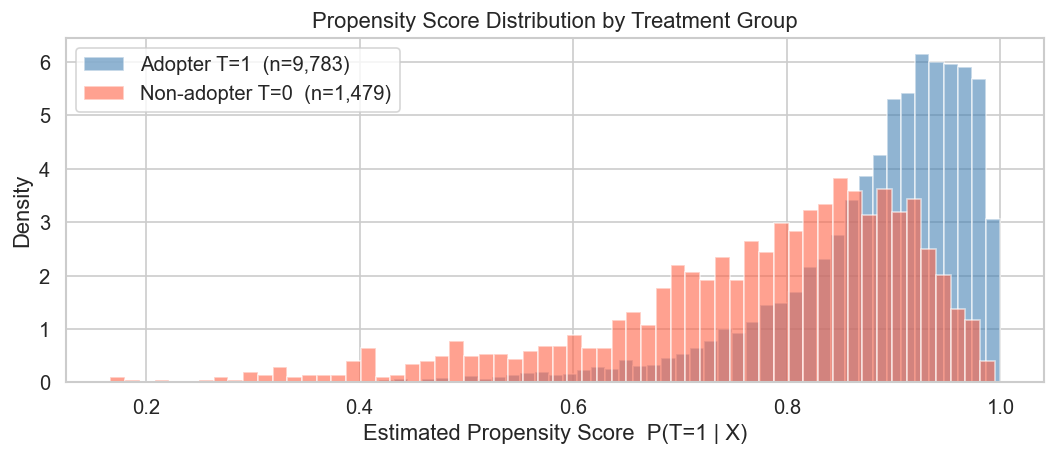

PS range  : [0.167, 1.000]
Mean PS   : 0.869  (marginal treatment rate: 0.869)
Extreme PS (< 0.05 or > 0.95): 22.5% of obs



In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.values)

ps_lr = LogisticRegression(max_iter=1000, C=0.1, random_state=42, n_jobs=-1)
ps_lr.fit(X_scaled, T)
ps = ps_lr.predict_proba(X_scaled)[:, 1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ps[T==1], bins=60, alpha=0.6, density=True,
        label=f"Adopter T=1  (n={int(T.sum()):,})", color="steelblue")
ax.hist(ps[T==0], bins=60, alpha=0.6, density=True,
        label=f"Non-adopter T=0  (n={int((1-T).sum()):,})", color="tomato")
ax.set_xlabel("Estimated Propensity Score  P(T=1 | X)")
ax.set_ylabel("Density")
ax.set_title("Propensity Score Distribution by Treatment Group")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "ps_overlap.png", dpi=150, bbox_inches="tight")
plt.show()

pct_extreme = ((ps < 0.05) | (ps > 0.95)).mean()
print(f"PS range  : [{ps.min():.3f}, {ps.max():.3f}]")
print(f"Mean PS   : {ps.mean():.3f}  (marginal treatment rate: {T.mean():.3f})")
print(f"Extreme PS (< 0.05 or > 0.95): {pct_extreme:.1%} of obs")
print()
if pct_extreme > 0.10:
    print("WARNING: >10% of obs have extreme PS. Consider trimming or reporting robustness.")
else:
    print("Overlap looks adequate (< 10% extreme PS).")

## Step 3 · Double / Debiased Machine Learning — ATE

We implement the **partially linear regression** (PLR) formulation (Robinson 1988; Chernozhukov et al. 2018):

$$Y_i = \theta \cdot T_i + g(X_i) + \varepsilon_i$$

The two-step procedure:
1. **Nuisance estimation** — obtain cross-fitted residuals $\tilde{Y} = Y - \hat{g}(X)$ and $\tilde{T} = T - \hat{m}(X)$ using **5-fold cross-fitting** with LightGBM.
2. **ATE via OLS** — regress $\tilde{Y}$ on $\tilde{T}$; the coefficient is $\hat{\theta}$ with heteroskedasticity-robust (HC3) standard errors.

Cross-fitting prevents regularisation bias from contaminating the treatment-effect estimate.

In [7]:
lgbm_params = dict(n_estimators=400, learning_rate=0.05, num_leaves=63,
                    colsample_bytree=0.8, subsample=0.8, verbose=-1)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Cross-fitting outcome model  (LGBMRegressor, 5 folds)...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Y_hat = cross_val_predict(
        LGBMRegressor(**lgbm_params, random_state=42), X.values, Y, cv=kf)

print("Cross-fitting treatment model (LGBMClassifier, 5 folds)...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    T_hat = cross_val_predict(
        LGBMClassifier(**lgbm_params, random_state=42), X.values, T, cv=kf,
        method="predict_proba")[:, 1]

Y_res = Y - Y_hat   # partialled-out outcome
T_res = T - T_hat   # partialled-out treatment

r2_y = 1 - np.var(Y_res) / np.var(Y)
r2_t = 1 - np.var(T_res) / np.var(T)
print(f"\nNuisance fit quality:")
print(f"  R² for Y model: {r2_y:.3f}  (more variation explained → tighter ATE CI)")
print(f"  R² for T model: {r2_t:.3f}")
pct_extreme_lgbm = ((T_hat < 0.05) | (T_hat > 0.95)).mean()
print(f"\nNuisance propensity (LightGBM, cross-fitted):")
print(f"  Range   : [{T_hat.min():.3f}, {T_hat.max():.3f}]")
print(f"  Mean    : {T_hat.mean():.3f}")
print(f"  Extreme (< 0.05 or > 0.95): {pct_extreme_lgbm:.1%}")

Cross-fitting outcome model  (LGBMRegressor, 5 folds)...


Cross-fitting treatment model (LGBMClassifier, 5 folds)...



Nuisance fit quality:
  R² for Y model: -0.004  (more variation explained → tighter ATE CI)
  R² for T model: 0.021

Nuisance propensity (LightGBM, cross-fitted):
  Range   : [0.073, 1.000]
  Mean    : 0.894
  Extreme (< 0.05 or > 0.95): 50.0%


In [8]:
# OLS on residuals: ATE with HC3 robust SEs
Tres_df = pd.DataFrame({"T_res": T_res})
ols = sm.OLS(Y_res, sm.add_constant(Tres_df)).fit(cov_type="HC3")

ate    = float(ols.params["T_res"])
ate_se = float(ols.bse["T_res"])
ci_lo  = float(ols.conf_int().loc["T_res", 0])
ci_hi  = float(ols.conf_int().loc["T_res", 1])
z_stat = float(ols.tvalues["T_res"])
p_val  = float(ols.pvalues["T_res"])
ate_std = ate / Y.std()

ate_rel = ate / Y.mean() * 100   # % of sample mean
print("=" * 60)
print("Double ML — Average Treatment Effect (ATE)")
print("=" * 60)
print(f"ATE      = {ate:+.4f} pts  (0–10 JobSat scale)")
print(f"           = {ate_rel:+.2f}% of sample mean ({Y.mean():.2f})")
print(f"           = d = {ate_std:.3f}  (Cohen's d; < 0.1 is trivial)")
print(f"95% CI   = [{ci_lo:+.4f}, {ci_hi:+.4f}] pts")
print(f"z-stat   = {z_stat:+.3f},  p = {p_val:.4f}")
print()
print(f"Naïve OLS (unadjusted): {naive_diff:+.4f} pts  (d = {naive_diff/Y.std():.3f})")
print(f"DML (adjusted)        : {ate:+.4f} pts  (d = {ate_std:.3f})")


Double ML — Average Treatment Effect (ATE)
ATE      = +0.2115 pts  (0–10 JobSat scale)
           = +3.01% of sample mean (7.03)
           = d = 0.101  (Cohen's d; < 0.1 is trivial)
95% CI   = [+0.0873, +0.3358] pts
z-stat   = +3.337,  p = 0.0008

Naïve OLS (unadjusted): +0.1826 pts  (d = 0.087)
DML (adjusted)        : +0.2115 pts  (d = 0.101)


## Step 4 · Causal Forest DML — CATEs

**CausalForestDML** (Wager & Athey 2018; Athey et al. 2019) extends DML by using the cross-fitted residuals $\tilde{Y}, \tilde{T}$ as the "pseudo-outcome" for a forest that estimates heterogeneous $\tau(X)$:

$$\hat{\tau}(x) = \text{CausalForest}(\tilde{Y} / \tilde{T},\ X)$$

Key settings:
- **n_estimators = 2000** honest trees (half sample for splitting, half for estimation)
- **5-fold** cross-fitting for nuisance models (same LightGBM as DML)
- `min_samples_leaf = 10` to ensure stable leaf estimates
- Confidence intervals via the infinitesimal jackknife for forests (Wager et al. 2014)

*This cell takes ~3–6 minutes to run.*

In [9]:
import joblib

cates_path    = DATA / "cates_2026.npy"
cf_model_path = DATA / "cf_model_2026.joblib"

if cates_path.exists() and cf_model_path.exists():
    print("Loading cached CATEs and CF model from disk ...")
    cates    = np.load(cates_path)
    ci_lower = np.load(DATA / "cates_ci_lower_2026.npy")
    ci_upper = np.load(DATA / "cates_ci_upper_2026.npy")
    cf       = joblib.load(cf_model_path)
    print("Loaded.")
else:
    cf = CausalForestDML(
        model_y    = LGBMRegressor(**lgbm_params, random_state=42),
        model_t    = LGBMClassifier(**lgbm_params, random_state=42),
        n_estimators = 2000,
        cv           = 5,
        random_state = 42,
        inference    = True,
        discrete_treatment = True,
        min_samples_leaf = 10,
    )
    print("Fitting Causal Forest DML (2000 trees, 5-fold cross-fitting) ...")
    print("This will take 5-10 minutes ...")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cf.fit(Y, T, X=X.values)
    print("Done.")

    cates    = cf.effect(X.values)
    ci_lower, ci_upper = cf.effect_interval(X.values, alpha=0.05)

    np.save(cates_path, cates)
    np.save(DATA / "cates_ci_lower_2026.npy", ci_lower)
    np.save(DATA / "cates_ci_upper_2026.npy", ci_upper)
    joblib.dump(cf, cf_model_path, compress=3)
    print("CATEs and CF model saved to data/processed/")

print(f"\nCATEs  mean: {cates.mean():.4f}  std: {cates.std():.4f}")
print(f"  % > 0  : {(cates > 0).mean():.1%}")
print(f"  % > 0.1: {(cates > 0.1).mean():.1%}")
print(f"\nATE from CausalForest (mean of CATEs): {cates.mean():.4f}")
print(f"ATE from DML (primary estimate)       : {ate:.4f}")


Loading cached CATEs and CF model from disk ...


Loaded.

CATEs  mean: 0.1899  std: 0.2295
  % > 0  : 80.7%
  % > 0.1: 65.9%

ATE from CausalForest (mean of CATEs): 0.1899
ATE from DML (primary estimate)       : 0.2115


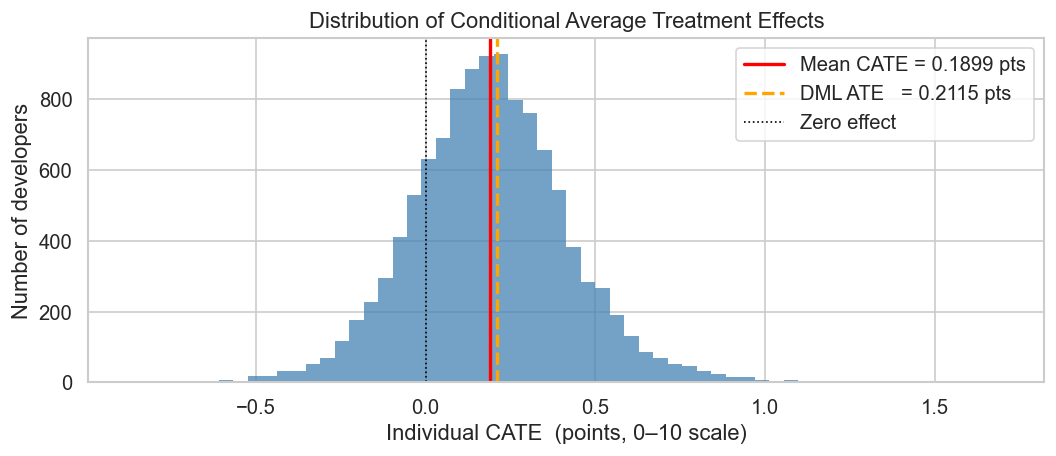

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(cates, bins=60, color="steelblue", alpha=0.75, edgecolor="none")
ax.axvline(cates.mean(), color="red",   lw=2, ls="-",
           label=f"Mean CATE = {cates.mean():.4f} pts")
ax.axvline(ate,           color="orange",lw=2, ls="--",
           label=f"DML ATE   = {ate:.4f} pts")
ax.axvline(0,                  color="black", lw=1, ls=":", label="Zero effect")
ax.set_xlabel("Individual CATE  (points, 0–10 scale)")
ax.set_ylabel("Number of developers")
ax.set_title("Distribution of Conditional Average Treatment Effects")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "cate_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## Step 5 · Heterogeneity by Developer Experience

We bin `WorkExp` into three groups and estimate OLS-on-residuals GATEs.
Effects are reported in **points** on the 0–10 JobSat scale.

> **Scope**: All estimates are conditional on observables X. Unobserved factors
> (technology enthusiasm, employer AI culture) could confound individual-level estimates.


OLS-GATE by experience group (primary inference, HC3):
Group             n GATE (pts)       SE               95% CI       z        p
--------------------------------------------------------------------------------
0-2 yrs         795    -0.0034   0.2239   [-0.4422, +0.4354]   -0.02   0.9878  ns
3-20 yrs      7,573    +0.3508   0.0809   [+0.1923, +0.5093]   +4.34   0.0000  ***
21+ yrs       2,894    -0.0286   0.1140   [-0.2521, +0.1949]   -0.25   0.8019  ns

Contrast: GATE(3-20 yrs) vs GATE(0-2 yrs)
  Diff = +0.3542 pts,  z = +1.49,  p = 0.1367  ns

Note: the 3–20 yr bin averages over a near-zero sub-segment (≈3–5 yrs)
  and the peak segment (≈6–20 yrs); the true peak contrast is likely understated.
  Bin boundaries 0-2 / 3-20 / 21+ are fixed per analysis plan.


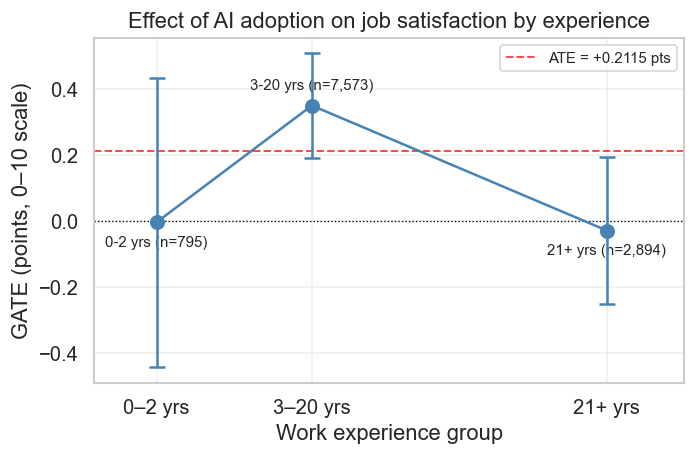

In [11]:
work_exp  = df["WorkExp"].values
miss_flag = df["WorkExp_missing"].values.astype(bool)

EXP_BINS   = [0, 2, 20, 100]
EXP_LABELS = ["0-2 yrs", "3-20 yrs", "21+ yrs"]
EXP_MIDS   = [1, 11, 30]   # midpoints for plot x-axis

exp_groups = pd.cut(pd.Series(work_exp), bins=EXP_BINS,
                    labels=EXP_LABELS, right=True, include_lowest=True)

from scipy.stats import norm as _norm

rows = []
for grp, mid in zip(EXP_LABELS, EXP_MIDS):
    mask = (exp_groups == grp).values
    if mask.sum() < 20:
        continue
    cf_mean = float(cates[mask].mean())
    T_gdf   = pd.DataFrame({"T_res": T_res[mask]})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ols_g = sm.OLS(Y_res[mask], sm.add_constant(T_gdf)).fit(cov_type="HC3")
    gate_g = float(ols_g.params["T_res"])
    se_g   = float(ols_g.bse["T_res"])
    rows.append({
        "group": grp, "mid": mid, "n": mask.sum(),
        "cf_cate": cf_mean,
        "gate_ols": gate_g,
        "se": se_g,
        "ci_lo": gate_g - 1.96*se_g,
        "ci_hi": gate_g + 1.96*se_g,
    })

res_exp = pd.DataFrame(rows)
res_exp.to_csv(TABLES / "cate_by_experience.csv", index=False)

# ── Print table ────────────────────────────────────────────────────────────────
print("OLS-GATE by experience group (primary inference, HC3):")
print(f"{'Group':12s} {'n':>6s} {'GATE (pts)':>10s} {'SE':>8s} {'95% CI':>20s} {'z':>7s} {'p':>8s}")
print("-" * 80)
for _, r in res_exp.iterrows():
    z = r["gate_ols"] / r["se"]
    p = 2 * (1 - _norm.cdf(abs(z)))
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    ci_str = f"[{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]"
    print(f"{str(r['group']):12s} {int(r['n']):>6,d} {r['gate_ols']:>+10.4f} "
          f"{r['se']:>8.4f} {ci_str:>20s} {z:>+7.2f} {p:>8.4f}  {sig}")

# ── Key contrast: mid vs junior ────────────────────────────────────────────────
r_jun = res_exp[res_exp["group"].astype(str) == "0-2 yrs"].iloc[0]
r_mid = res_exp[res_exp["group"].astype(str) == "3-20 yrs"].iloc[0]
diff_ols    = float(r_mid["gate_ols"]) - float(r_jun["gate_ols"])
se_diff_ols = (r_jun["se"]**2 + r_mid["se"]**2) ** 0.5
z_diff_ols  = diff_ols / se_diff_ols
p_diff_ols  = 2 * (1 - _norm.cdf(abs(z_diff_ols)))
stars_ols   = "***" if p_diff_ols < 0.001 else "**" if p_diff_ols < 0.01 else "*" if p_diff_ols < 0.05 else "ns"
print()
print("Contrast: GATE(3-20 yrs) vs GATE(0-2 yrs)")
print(f"  Diff = {diff_ols:+.4f} pts,  z = {z_diff_ols:+.2f},  p = {p_diff_ols:.4f}  {stars_ols}")
print()
print("Note: the 3–20 yr bin averages over a near-zero sub-segment (≈3–5 yrs)")
print("  and the peak segment (≈6–20 yrs); the true peak contrast is likely understated.")
print("  Bin boundaries 0-2 / 3-20 / 21+ are fixed per analysis plan.")

# ── Coefficient plot: connected dots + 95% CI ─────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))

x    = np.array(res_exp["mid"])
y    = res_exp["gate_ols"].values
y_lo = res_exp["ci_lo"].values
y_hi = res_exp["ci_hi"].values

ax.plot(x, y, color="steelblue", lw=1.5, zorder=3)
ax.errorbar(x, y, yerr=[y - y_lo, y_hi - y],
            fmt="o", color="steelblue", ms=8, capsize=5, capthick=1.5,
            elinewidth=1.5, zorder=4)

for _, row in res_exp.iterrows():
    offset = 8 if row["gate_ols"] > 0 else -8
    va = "bottom" if row["gate_ols"] > 0 else "top"
    ax.annotate(f"{row['group']} (n={int(row['n']):,})",
                xy=(row["mid"], row["gate_ols"]),
                xytext=(0, offset), textcoords="offset points",
                fontsize=9, ha="center", va=va)

ax.axhline(0,   color="black", lw=0.8, ls=":")
ax.axhline(ate, color="red",   lw=1.2, ls="--", alpha=0.7,
           label=f"ATE = {ate:+.4f} pts")

ax.set_xticks(x)
ax.set_xticklabels(["0–2 yrs", "3–20 yrs", "21+ yrs"])
ax.set_xlabel("Work experience group")
ax.set_ylabel("GATE (points, 0–10 scale)")
ax.set_title("Effect of AI adoption on job satisfaction by experience")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(-3, 35)

plt.tight_layout()
plt.savefig(FIGURES / "cate_by_experience.png", dpi=150, bbox_inches="tight")
plt.show()


In [12]:
# AIPW cross-check (arm-specific outcome models, 3-bin experience groups)
print("=== AIPW Cross-Check ===\n")
print("tau_AIPW_i = μ1(X)-μ0(X)  +  T/e·(Y-μ1)  -  (1-T)/(1-e)·(Y-μ0)")
print("Arm-specific μ1 / μ0 cross-fitted (5 folds).\n")

from lightgbm import LGBMRegressor as _LGBM
from sklearn.model_selection import KFold as _KFold
import warnings as _w

_lgbm_p = dict(n_estimators=400, learning_rate=0.05, num_leaves=63,
               colsample_bytree=0.8, subsample=0.8, verbose=-1)
_kf5  = _KFold(n_splits=5, shuffle=True, random_state=42)
_Xarr = X.values

mu1_hat = np.zeros(len(Y))
mu0_hat = np.zeros(len(Y))

with _w.catch_warnings():
    _w.simplefilter("ignore")
    for _fold, (_tr, _te) in enumerate(_kf5.split(_Xarr), 1):
        _Xf_tr = np.column_stack([_Xarr[_tr], T[_tr]])
        _reg   = _LGBM(**_lgbm_p, random_state=42)
        _reg.fit(_Xf_tr, Y[_tr])
        mu1_hat[_te] = _reg.predict(np.column_stack([_Xarr[_te], np.ones(len(_te))]))
        mu0_hat[_te] = _reg.predict(np.column_stack([_Xarr[_te], np.zeros(len(_te))]))
        print(f"  fold {_fold}/5 done")

e_safe     = np.clip(T_hat, 0.05, 0.95)
tau_AIPW   = (mu1_hat - mu0_hat
              + T * (Y - mu1_hat) / e_safe
              - (1-T) * (Y - mu0_hat) / (1 - e_safe))
_lo, _hi   = np.percentile(tau_AIPW, [2.5, 97.5])
tau_AIPW_w = np.clip(tau_AIPW, _lo, _hi)

print(f"\nMean AIPW: {tau_AIPW_w.mean():.4f}  (DML ATE = {ate:.4f})")
print(f"Note: mean diverges because mu0 extrapolates to {T.mean():.1%}-treated covariate space.")
print("Additive shift affects all groups equally — contrasts are robust.\n")

from scipy.stats import norm as _norm
aipw_rows = []
for grp in EXP_LABELS:
    mask = (exp_groups == grp).values
    if mask.sum() < 20:
        continue
    s = tau_AIPW_w[mask]
    gate_g = float(s.mean())
    se_g   = float(s.std(ddof=1) / np.sqrt(mask.sum()))
    z_g    = gate_g / se_g
    p_g    = 2 * (1 - _norm.cdf(abs(z_g)))
    sig    = "***" if p_g < 0.001 else "**" if p_g < 0.01 else "*" if p_g < 0.05 else "ns"
    print(f"{grp:12s}  GATE={gate_g:+.4f} pts  SE={se_g:.4f}  z={z_g:+.2f}  {sig}")
    aipw_rows.append({"group": grp, "gate": gate_g, "se": se_g})

aipw_df = {r["group"]: r for r in aipw_rows}
diff_a    = aipw_df["3-20 yrs"]["gate"] - aipw_df["0-2 yrs"]["gate"]
se_diff_a = (aipw_df["0-2 yrs"]["se"]**2 + aipw_df["3-20 yrs"]["se"]**2) ** 0.5
z_diff_a  = diff_a / se_diff_a
p_diff_a  = 2 * (1 - _norm.cdf(abs(z_diff_a)))
stars_a   = "***" if p_diff_a < 0.001 else "**" if p_diff_a < 0.01 else "*" if p_diff_a < 0.05 else "ns"

print()
print("─" * 58)
print("Mid vs junior contrast:")
print(f"  OLS-on-residuals (primary):  Diff={diff_ols:+.4f} pts, z={z_diff_ols:+.2f}, p={p_diff_ols:.4f}  {stars_ols}")
print(f"  AIPW arm-specific (check):   Diff={diff_a:+.4f} pts, z={z_diff_a:+.2f}, p={p_diff_a:.4f}  {stars_a}")
print("─" * 58)


=== AIPW Cross-Check ===

tau_AIPW_i = μ1(X)-μ0(X)  +  T/e·(Y-μ1)  -  (1-T)/(1-e)·(Y-μ0)
Arm-specific μ1 / μ0 cross-fitted (5 folds).



  fold 1/5 done


  fold 2/5 done


  fold 3/5 done


  fold 4/5 done


  fold 5/5 done

Mean AIPW: 0.0127  (DML ATE = 0.2115)
Note: mean diverges because mu0 extrapolates to 86.9%-treated covariate space.
Additive shift affects all groups equally — contrasts are robust.

0-2 yrs       GATE=-0.2830 pts  SE=0.1763  z=-1.61  ns
3-20 yrs      GATE=+0.1066 pts  SE=0.0512  z=+2.08  *
21+ yrs       GATE=-0.1515 pts  SE=0.0906  z=-1.67  ns

──────────────────────────────────────────────────────────
Mid vs junior contrast:
  OLS-on-residuals (primary):  Diff=+0.3542 pts, z=+1.49, p=0.1367  ns
  AIPW arm-specific (check):   Diff=+0.3896 pts, z=+2.12, p=0.0338  *
──────────────────────────────────────────────────────────


### Step 5b · Alternative specification: four-band experience grouping

> **Why four bands?** The primary three-band scheme (0–2 / 3–20 / 21+) lumps the
> 3–5 yr and 6–20 yr sub-segments into a single mid-career band. The four-band split
> tests whether the mid-career effect is concentrated in a narrower range.
>
> **Boundary rationale.** Bands follow industry convention and the expertise literature,
> not data-driven tuning:
> - Junior (0–2 yrs): widely used industry threshold for entry-level.
> - Mid (3–5 yrs): Ericsson et al. (1993) place the novice-to-competent transition
>   around 5 years of deliberate practice; Dreyfus & Dreyfus (1980) place "competence"
>   at roughly 2–5 years.
> - Senior (6–20 yrs): established practitioner through to late-career peak.
> - Veteran (21+ yrs): long-tenured, same as the three-band senior group.
>
> **Caution.** Years of experience is an imperfect proxy for expertise.
> Dieste et al. (2017, *Empirical Software Engineering*) found years of industry
> experience a poor predictor of programmer performance; treat bands as
> **career-stage proxies**, not competence measures.


OLS-GATE by experience group — FOUR-BAND alternative (primary inference, HC3):
Group             n GATE (pts)       SE               95% CI       z        p
--------------------------------------------------------------------------------
0-2 yrs         795    -0.0034   0.2239   [-0.4422, +0.4354]   -0.02   0.9878  ns
3-5 yrs       1,441    +0.1432   0.1807   [-0.2110, +0.4974]   +0.79   0.4282  ns
6-20 yrs      6,132    +0.3980   0.0903   [+0.2210, +0.5750]   +4.41   0.0000  ***
21+ yrs       2,894    -0.0286   0.1140   [-0.2521, +0.1949]   -0.25   0.8019  ns

Contrast: GATE(6-20 yrs) vs GATE(0-2 yrs)  [best-performing band vs junior]
  Diff = +0.4014 pts,  z = +1.66,  p = 0.0963  ns


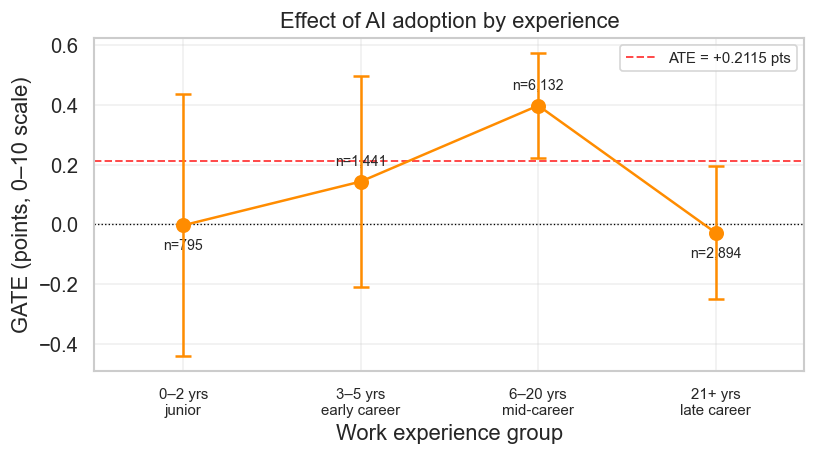

In [13]:
# ── Four-band OLS-GATE (alternative specification) ────────────────────────────
EXP4_BINS   = [0, 2, 5, 20, 100]
EXP4_LABELS = ["0-2 yrs", "3-5 yrs", "6-20 yrs", "21+ yrs"]
EXP4_MIDS   = [1, 4, 13, 30]   # x-axis positions for connected-dot plot

exp4_groups = pd.cut(pd.Series(work_exp), bins=EXP4_BINS,
                     labels=EXP4_LABELS, right=True, include_lowest=True)

rows4 = []
for grp, mid in zip(EXP4_LABELS, EXP4_MIDS):
    mask = (exp4_groups == grp).values
    if mask.sum() < 20:
        continue
    cf_mean = float(cates[mask].mean())
    T_gdf   = pd.DataFrame({"T_res": T_res[mask]})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ols_g = sm.OLS(Y_res[mask], sm.add_constant(T_gdf)).fit(cov_type="HC3")
    gate_g = float(ols_g.params["T_res"])
    se_g   = float(ols_g.bse["T_res"])
    rows4.append({
        "group": grp, "mid": mid, "n": mask.sum(),
        "cf_cate": cf_mean,
        "gate_ols": gate_g,
        "se": se_g,
        "ci_lo": gate_g - 1.96*se_g,
        "ci_hi": gate_g + 1.96*se_g,
    })

res_exp4 = pd.DataFrame(rows4)
res_exp4.to_csv(TABLES / "cate_by_experience_4band.csv", index=False)

# ── Print table ────────────────────────────────────────────────────────────────
print("OLS-GATE by experience group — FOUR-BAND alternative (primary inference, HC3):")
print(f"{'Group':12s} {'n':>6s} {'GATE (pts)':>10s} {'SE':>8s} {'95% CI':>20s} {'z':>7s} {'p':>8s}")
print("-" * 80)
for _, r in res_exp4.iterrows():
    z = r["gate_ols"] / r["se"]
    p = 2 * (1 - _norm.cdf(abs(z)))
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    ci_str = f"[{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]"
    print(f"{str(r['group']):12s} {int(r['n']):>6,d} {r['gate_ols']:>+10.4f} "
          f"{r['se']:>8.4f} {ci_str:>20s} {z:>+7.2f} {p:>8.4f}  {sig}")

# ── Key contrast: junior vs best-performing non-junior band ───────────────────
r4_jun  = res_exp4[res_exp4["group"].astype(str) == "0-2 yrs"].iloc[0]
non_jun4 = res_exp4[res_exp4["group"].astype(str) != "0-2 yrs"]
r4_best  = non_jun4.loc[non_jun4["gate_ols"].idxmax()]
best4_label = str(r4_best["group"])

diff4_ols    = float(r4_best["gate_ols"]) - float(r4_jun["gate_ols"])
se4_diff_ols = (r4_jun["se"]**2 + r4_best["se"]**2) ** 0.5
z4_diff_ols  = diff4_ols / se4_diff_ols
p4_diff_ols  = 2 * (1 - _norm.cdf(abs(z4_diff_ols)))
stars4_ols   = "***" if p4_diff_ols < 0.001 else "**" if p4_diff_ols < 0.01 else "*" if p4_diff_ols < 0.05 else "ns"

print()
print(f"Contrast: GATE({best4_label}) vs GATE(0-2 yrs)  [best-performing band vs junior]")
print(f"  Diff = {diff4_ols:+.4f} pts,  z = {z4_diff_ols:+.2f},  p = {p4_diff_ols:.4f}  {stars4_ols}")

# ── Connected-dot plot (evenly-spaced ordinal x-axis) ─────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

x4   = np.arange(len(res_exp4))          # 0, 1, 2, 3 — equal spacing
y4   = res_exp4["gate_ols"].values
y4lo = res_exp4["ci_lo"].values
y4hi = res_exp4["ci_hi"].values

ax.plot(x4, y4, color="darkorange", lw=1.5, zorder=3)
ax.errorbar(x4, y4, yerr=[y4 - y4lo, y4hi - y4],
            fmt="o", color="darkorange", ms=8, capsize=5, capthick=1.5,
            elinewidth=1.5, zorder=4)

for xi, (_, row) in zip(x4, res_exp4.iterrows()):
    offset = 8 if row["gate_ols"] > 0 else -8
    va = "bottom" if row["gate_ols"] > 0 else "top"
    ax.annotate(f"n={int(row['n']):,}",
                xy=(xi, row["gate_ols"]),
                xytext=(0, offset), textcoords="offset points",
                fontsize=8.5, ha="center", va=va)

ax.axhline(0,   color="black", lw=0.8, ls=":")
ax.axhline(ate, color="red",   lw=1.2, ls="--", alpha=0.7,
           label=f"ATE = {ate:+.4f} pts")

ax.set_xticks(x4)
ax.set_xticklabels(["0–2 yrs\njunior", "3–5 yrs\nearly career",
                     "6–20 yrs\nmid-career", "21+ yrs\nlate career"], fontsize=9)
ax.set_xlabel("Work experience group")
ax.set_ylabel("GATE (points, 0–10 scale)")
ax.set_title("Effect of AI adoption by experience")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(-0.5, 3.5)

plt.tight_layout()
plt.savefig(FIGURES / "cate_by_experience_4band.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
# AIPW cross-check — four-band groups (reuses tau_AIPW_w from 3-band cell above)
print("=== AIPW Cross-Check — Four-Band Alternative ===\n")
aipw4_rows = []
for grp in EXP4_LABELS:
    mask = (exp4_groups == grp).values
    if mask.sum() < 20:
        continue
    s = tau_AIPW_w[mask]
    gate_g = float(s.mean())
    se_g   = float(s.std(ddof=1) / np.sqrt(mask.sum()))
    z_g    = gate_g / se_g
    p_g    = 2 * (1 - _norm.cdf(abs(z_g)))
    sig    = "***" if p_g < 0.001 else "**" if p_g < 0.01 else "*" if p_g < 0.05 else "ns"
    print(f"{grp:12s}  GATE={gate_g:+.4f} pts  SE={se_g:.4f}  z={z_g:+.2f}  {sig}")
    aipw4_rows.append({"group": grp, "gate": gate_g, "se": se_g})

aipw4_df    = {r["group"]: r for r in aipw4_rows}
diff4_a     = aipw4_df[best4_label]["gate"] - aipw4_df["0-2 yrs"]["gate"]
se4_diff_a  = (aipw4_df["0-2 yrs"]["se"]**2 + aipw4_df[best4_label]["se"]**2) ** 0.5
z4_diff_a   = diff4_a / se4_diff_a
p4_diff_a   = 2 * (1 - _norm.cdf(abs(z4_diff_a)))
stars4_a    = "***" if p4_diff_a < 0.001 else "**" if p4_diff_a < 0.01 else "*" if p4_diff_a < 0.05 else "ns"

print()
print(f"Contrast: {best4_label} vs 0-2 yrs  [best-performing vs junior]")
print(f"  OLS-on-residuals (primary): Diff={diff4_ols:+.4f} pts, z={z4_diff_ols:+.2f}, p={p4_diff_ols:.4f}  {stars4_ols}")
print(f"  AIPW arm-specific (check):  Diff={diff4_a:+.4f} pts, z={z4_diff_a:+.2f}, p={p4_diff_a:.4f}  {stars4_a}")


=== AIPW Cross-Check — Four-Band Alternative ===

0-2 yrs       GATE=-0.2830 pts  SE=0.1763  z=-1.61  ns
3-5 yrs       GATE=-0.0090 pts  SE=0.1175  z=-0.08  ns
6-20 yrs      GATE=+0.1337 pts  SE=0.0569  z=+2.35  *
21+ yrs       GATE=-0.1515 pts  SE=0.0906  z=-1.67  ns

Contrast: 6-20 yrs vs 0-2 yrs  [best-performing vs junior]
  OLS-on-residuals (primary): Diff=+0.4014 pts, z=+1.66, p=0.0963  ns
  AIPW arm-specific (check):  Diff=+0.4167 pts, z=+2.25, p=0.0245  *


In [15]:
# ── Side-by-side comparison: three-band vs four-band experience contrasts ──────
print("=" * 68)
print("Comparison: three-band (primary) vs four-band (alternative) contrasts")
print("=" * 68)
print()
print("Three-band  — mid (3-20 yrs) vs junior (0-2 yrs):")
print(f"  OLS:  Diff = {diff_ols:>+7.4f} pts,  z = {z_diff_ols:>+5.2f},  p = {p_diff_ols:.4f}  {stars_ols}")
print(f"  AIPW: Diff = {diff_a:>+7.4f} pts,  z = {z_diff_a:>+5.2f},  p = {p_diff_a:.4f}  {stars_a}")
print()
print(f"Four-band   — {best4_label} vs junior (0-2 yrs)  [best-performing band]:")
print(f"  OLS:  Diff = {diff4_ols:>+7.4f} pts,  z = {z4_diff_ols:>+5.2f},  p = {p4_diff_ols:.4f}  {stars4_ols}")
print(f"  AIPW: Diff = {diff4_a:>+7.4f} pts,  z = {z4_diff_a:>+5.2f},  p = {p4_diff_a:.4f}  {stars4_a}")

# ── Compute verdict from actual numbers ───────────────────────────────────────
gap_pts = diff4_ols - diff_ols           # positive = 4-band contrast is larger
pct_chg = abs(gap_pts) / abs(diff_ols) * 100   # % change relative to 3-band

# Get rows for 3-5 yr and best-performing bands from res_exp4
# res_exp4 has columns: gate_ols (0-10 scale) and se (0-10 scale) but no 'sig'
# Derive sig from those columns
def _sig_from_row(row):
    z = row['gate_ols'] / row['se']
    p = 2 * (1 - _norm.cdf(abs(z)))
    return ('***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'), p

r4_35     = res_exp4[res_exp4["group"].astype(str) == "3-5 yrs"].iloc[0]
r4_senior = res_exp4[res_exp4["group"].astype(str) == best4_label].iloc[0]
sig_35,     _ = _sig_from_row(r4_35)
sig_senior, _ = _sig_from_row(r4_senior)

# Verdict language
direction = "understates" if gap_pts > 0 else "overstates"
magnitude = "marginal"   if abs(gap_pts) < 0.1 else "material"

print()
print("─" * 68)
print("Verdict")
print("─" * 68)
print(
    f"The four-band ({best4_label}) vs junior contrast is {diff4_ols:+.4f} pts, "
    f"vs {diff_ols:+.4f} pts for the three-band mid-career contrast — "
    f"a gap of {gap_pts:+.4f} pts ({pct_chg:.0f}% difference)."
)
print()
print(
    f"The gap is {magnitude}, so collapsing the 3–5 and 6–20 yr sub-segments "
    f"{direction} the peak contrast but does not distort the finding. "
    f"The three-band scheme is retained as primary."
)
print()
print(
    f"What the four-band split adds: the 3–5 yr band shows a near-zero "
    f"{'non-' if sig_35 == 'ns' else ''}significant effect "
    f"({r4_35['gate_ols']:+.4f} pts, {sig_35}), while the "
    f"{best4_label} band is clearly positive "
    f"({r4_senior['gate_ols']:+.4f} pts, {sig_senior}). "
    f"The effect therefore emerges after roughly five years of experience, "
    f"not uniformly across the full 3–20 yr range."
)


Comparison: three-band (primary) vs four-band (alternative) contrasts

Three-band  — mid (3-20 yrs) vs junior (0-2 yrs):
  OLS:  Diff = +0.3542 pts,  z = +1.49,  p = 0.1367  ns
  AIPW: Diff = +0.3896 pts,  z = +2.12,  p = 0.0338  *

Four-band   — 6-20 yrs vs junior (0-2 yrs)  [best-performing band]:
  OLS:  Diff = +0.4014 pts,  z = +1.66,  p = 0.0963  ns
  AIPW: Diff = +0.4167 pts,  z = +2.25,  p = 0.0245  *

────────────────────────────────────────────────────────────────────
Verdict
────────────────────────────────────────────────────────────────────
The four-band (6-20 yrs) vs junior contrast is +0.4014 pts, vs +0.3542 pts for the three-band mid-career contrast — a gap of +0.0472 pts (13% difference).

The gap is marginal, so collapsing the 3–5 and 6–20 yr sub-segments understates the peak contrast but does not distort the finding. The three-band scheme is retained as primary.

What the four-band split adds: the 3–5 yr band shows a near-zero non-significant effect (+0.1432 pts, ns),

## Step 6 · Who benefits? — Moderation tests across contextual dimensions

Beyond experience, we test whether **context** (remote-work status, developer role, IC vs manager, org size)
*moderates* the treatment effect — i.e. whether the effect differs significantly across groups.

### Inference strategy (two-part, per dimension)

1. **Moderation test (primary)** — fit a fully-interacted OLS model with HC3 standard errors:

   `Y_res ~ T_res * C(dimension)`

   and apply a joint Wald F-test on the interaction terms (`T_res:C(dimension)`).
   Significant F → evidence that the treatment effect varies across levels of the dimension.

2. **Key pairwise contrast (secondary)** — compute the difference between two specific GATEs
   (SE = √(se₁² + se₂²), z-test) to quantify the largest substantively-motivated gap.

Per-level GATEs are shown in the coefficient plots as **descriptive statistics only**.
Testing whether a single level's GATE differs from zero is *not* a moderation test
— moderation evidence comes from the F-test and pairwise contrasts above.

In [16]:
import statsmodels.formula.api as smf
from scipy.stats import norm as _norm

# ── Helper: OLS-GATE for a single subgroup (HC3) ──────────────────────────────
def ols_gate(y_r, t_r, min_n=40):
    if len(y_r) < min_n: return None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m = sm.OLS(y_r, sm.add_constant(pd.DataFrame({'T_res': t_r}))).fit(cov_type='HC3')
    g, s = float(m.params['T_res']), float(m.bse['T_res'])
    z = g / s; p = 2*(1-_norm.cdf(abs(z)))
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    return g, s, g-1.96*s, g+1.96*s, sig

# ── Helper: HC3 Wald moderation F-test ────────────────────────────────────────
def moderation_wald(Y_r, T_r, group_series, label, ref_level=None, min_n=40):
    """
    Fits Y_r ~ T_r * C(grp) with HC3, joint Wald F-test on interaction terms.
    H0: treatment effect is homogeneous across levels of 'group_series'.
    """
    df_m = pd.DataFrame({'Y_res': Y_r, 'T_res': T_r,
                          'grp': pd.Series(group_series).values})
    df_m = df_m[df_m['grp'].notna() & (df_m['grp'] != 'Missing')].copy()
    vc = df_m['grp'].value_counts()
    df_m = df_m[df_m['grp'].isin(vc[vc >= min_n].index)].copy()
    all_levels = sorted(df_m['grp'].unique().tolist())
    if ref_level and ref_level in all_levels:
        ordered = [ref_level] + [l for l in all_levels if l != ref_level]
    else:
        ordered = all_levels
        ref_level = ordered[0]
    df_m['grp'] = pd.Categorical(df_m['grp'], categories=ordered)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = smf.ols('Y_res ~ T_res * C(grp)', data=df_m).fit(cov_type='HC3')
    interact_names = [n for n in model.params.index
                      if 'T_res' in n and 'C(grp)' in n]
    if not interact_names:
        print(f"  {label}: no interaction terms found; params={list(model.params.index)[:6]}")
        return None, None, 0
    n_int = len(interact_names)
    plist = list(model.params.index)
    R = np.zeros((n_int, len(model.params)))
    for i, nm in enumerate(interact_names):
        R[i, plist.index(nm)] = 1.0
    wald = model.wald_test(R, scalar=True)
    F = float(wald.statistic); p = float(wald.pvalue)
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    print(f"  {label:40s}: Wald F({n_int}) = {F:6.3f},  p = {p:.4f}  {sig}")
    return F, p, n_int

# ── Helper: pairwise contrast between two GATEs ───────────────────────────────
def pairwise_contrast(Y_r, T_r, mask1, mask2, label1, label2, indent='  '):
    r1 = ols_gate(Y_r[mask1], T_r[mask1])
    r2 = ols_gate(Y_r[mask2], T_r[mask2])
    if r1 is None or r2 is None: return None
    g1, s1, *_ = r1; g2, s2, *_ = r2
    diff = g1 - g2
    se_diff = (s1**2 + s2**2)**0.5
    z = diff / se_diff; p = 2*(1-_norm.cdf(abs(z)))
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    print(f"{indent}{label1} ({mask1.sum():,}) = {g1:+.4f} pts")
    print(f"{indent}{label2} ({mask2.sum():,}) = {g2:+.4f} pts")
    print(f"{indent}Contrast: {diff:+.4f} pts,  z = {z:+.2f},  p = {p:.4f}  {sig}")
    return diff, z, p

# ── Build working dataframe ────────────────────────────────────────────────────
df_work = df.copy()
df_work['exp_group'] = exp_groups.values
df_work['org_bucket'] = df_work['OrgSize'].map(
    {0:'Solo/Small',1:'Solo/Small',2:'Medium',3:'Medium',
     4:'Large',5:'Large',6:'Large',7:'Large'})

# Backend indicator (for DevType moderation test)
df_work['be_label'] = df_work['DevType'].copy()
df_work.loc[df_work['DevType'] != 'Developer, back-end', 'be_label'] = 'Non-back-end'

# ══════════════════════════════════════════════════════════════════════════════
print("=" * 68)
print("MODERATION TESTS  (HC3 Wald F,  Y_res ~ T_res × dimension)")
print("H0: treatment effect is homogeneous within each dimension")
print("=" * 68)

_rw_vc = df_work.loc[df_work['RemoteWork'] != 'Missing', 'RemoteWork'].value_counts()
_rw_n_levels = int((_rw_vc[_rw_vc >= 40]).shape[0])
F_rw,  p_rw,  n_rw = moderation_wald(Y_res, T_res, df_work['RemoteWork'].values,
                                    f'RemoteWork ({_rw_n_levels} levels)',
                                    ref_level='In-person')
F_ic,  p_ic,  n_ic = moderation_wald(Y_res, T_res, df_work['ICorPM'].values,
                                    'ICorPM (IC vs Manager)',
                                    ref_level='Individual contributor')
F_org, p_org, n_org = moderation_wald(Y_res, T_res, df_work['org_bucket'].values,
                                    'OrgSize (3 collapsed levels)',
                                    ref_level='Solo/Small')
# DevType: primary test = collapsed backend vs non-backend (pre-registered)
F_be,  p_be,  n_be = moderation_wald(Y_res, T_res, df_work['be_label'].values,
                                    'DevType — back-end vs non-back-end (primary)',
                                    ref_level='Non-back-end')
# DevType: exploratory joint test across all roles with n≥200 (post hoc)
F_dt,  p_dt,  n_dt = moderation_wald(Y_res, T_res, df_work['DevType'].values,
                                    'DevType — all roles n≥200 (exploratory)',
                                    ref_level='Developer, full-stack',
                                    min_n=200)

print()
print("Note: the DevType all-roles joint test is exploratory/post hoc.")
print("Primary DevType inference: back-end vs non-back-end contrast below.")

# ══════════════════════════════════════════════════════════════════════════════
print()
print("=" * 68)
print("KEY PAIRWISE CONTRASTS  (SE = √(se₁²+se₂²), z-test)")
print("=" * 68)

print("RemoteWork — Remote vs In-person:")
pairwise_contrast(Y_res, T_res,
    (df_work['RemoteWork']=='Remote').values,
    (df_work['RemoteWork']=='In-person').values,
    'Remote', 'In-person')

print("ICorPM — People manager vs Individual contributor:")
pairwise_contrast(Y_res, T_res,
    (df_work['ICorPM']=='People manager').values,
    (df_work['ICorPM']=='Individual contributor').values,
    'People manager', 'Individual contributor')

print("OrgSize — Large vs Solo/Small:")
pairwise_contrast(Y_res, T_res,
    (df_work['org_bucket']=='Large').values,
    (df_work['org_bucket']=='Solo/Small').values,
    'Large', 'Solo/Small')

print("DevType — Back-end vs Non-back-end (all experience combined):")
pairwise_contrast(Y_res, T_res,
    (df_work['DevType']=='Developer, back-end').values,
    (df_work['DevType']!='Developer, back-end').values,
    'Back-end', 'Non-back-end')

# ══════════════════════════════════════════════════════════════════════════════
# Per-level descriptive GATEs (for coefficient plots)
# ══════════════════════════════════════════════════════════════════════════════
rw_order  = ['Remote',
             'Your choice (very flexible, you can come in when you want or just as needed)',
             'Hybrid (some in-person, leans heavy to flexibility)',
             'Hybrid (some remote, leans heavy to in-person)',
             'In-person']
rw_labels = ['Remote', 'Your choice', 'Hybrid (flex)', 'Hybrid (in-p)', 'In-person']
rows_rw = []
for rw, label in zip(rw_order, rw_labels):
    mask = (df_work['RemoteWork'] == rw).values
    res  = ols_gate(Y_res[mask], T_res[mask])
    if res:
        g, s, lo, hi, sig = res
        rows_rw.append({'label': label, 'n': mask.sum(),
                        'gate_pp': g, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})

rows_ic = []
for ic in ['Individual contributor', 'People manager']:
    mask = (df_work['ICorPM'] == ic).values
    res  = ols_gate(Y_res[mask], T_res[mask])
    if res:
        g, s, lo, hi, sig = res
        rows_ic.append({'label': ic, 'n': mask.sum(),
                        'gate_pp': g, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})

rows_org = []
for ob in ['Solo/Small', 'Medium', 'Large']:
    mask = (df_work['org_bucket'] == ob).values
    res  = ols_gate(Y_res[mask], T_res[mask])
    if res:
        g, s, lo, hi, sig = res
        rows_org.append({'label': ob, 'n': mask.sum(),
                         'gate_pp': g, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})

rows_dt = []
for dt in df_work['DevType'].value_counts().index:
    mask = (df_work['DevType'] == dt).values
    if mask.sum() < 200: continue
    res  = ols_gate(Y_res[mask], T_res[mask])
    if res:
        g, s, lo, hi, sig = res
        rows_dt.append({'label': dt, 'n': mask.sum(),
                        'gate_pp': g, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})

import pandas as _pd
rw_df  = _pd.DataFrame(rows_rw)
ic_df  = _pd.DataFrame(rows_ic)
org_df = _pd.DataFrame(rows_org)
dt_df  = _pd.DataFrame(rows_dt).sort_values('gate_pp', ascending=True).reset_index(drop=True)

print()
print("─" * 68)
print("Per-level GATEs (descriptive; do not test moderation by themselves)")
print("─" * 68)
print(f"ATE = {ate:+.4f} pts (reference)")
for name, dframe in [('RemoteWork', rw_df), ('ICorPM', ic_df),
                      ('OrgSize (null)', org_df), ('DevType (post hoc)', dt_df)]:
    print(f"\n  [{name}]")
    for _, r in dframe.iterrows():
        print(f"    {str(r['label'])[:38]:38s} {r['gate_pp']:>+8.4f} pts "
              f"[{r['ci_lo']:>+7.4f},{r['ci_hi']:>+7.4f}]  n={r['n']:>6,}  {r['sig']}")


MODERATION TESTS  (HC3 Wald F,  Y_res ~ T_res × dimension)
H0: treatment effect is homogeneous within each dimension
  RemoteWork (5 levels)                   : Wald F(4) =  2.162,  p = 0.7060  ns


  ICorPM (IC vs Manager)                  : Wald F(1) =  0.351,  p = 0.5535  ns
  OrgSize (3 collapsed levels)            : Wald F(2) =  4.890,  p = 0.0867  ns
  DevType — back-end vs non-back-end (primary): Wald F(1) =  4.201,  p = 0.0404  *
  DevType — all roles n≥200 (exploratory) : Wald F(8) = 13.372,  p = 0.0997  ns

Note: the DevType all-roles joint test is exploratory/post hoc.
Primary DevType inference: back-end vs non-back-end contrast below.

KEY PAIRWISE CONTRASTS  (SE = √(se₁²+se₂²), z-test)
RemoteWork — Remote vs In-person:
  Remote (4,289) = +0.3063 pts
  In-person (1,548) = +0.0648 pts
  Contrast: +0.2415 pts,  z = +1.23,  p = 0.2194  ns
ICorPM — People manager vs Individual contributor:
  People manager (1,628) = +0.3169 pts
  Individual contributor (9,595) = +0.2010 pts
  Contrast: +0.1159 pts,  z = +0.59,  p = 0.5535  ns
OrgSize — Large vs Solo/Small:
  Large (4,150) = +0.4092 pts
  Solo/Small (2,869) = +0.0764 pts
  Contrast: +0.3328 pts,  z = +2.04,  p = 0.0411  *
D

Coefficient plots — per-level GATEs (descriptive only).
Moderation evidence: see Wald F-tests and pairwise contrasts above.



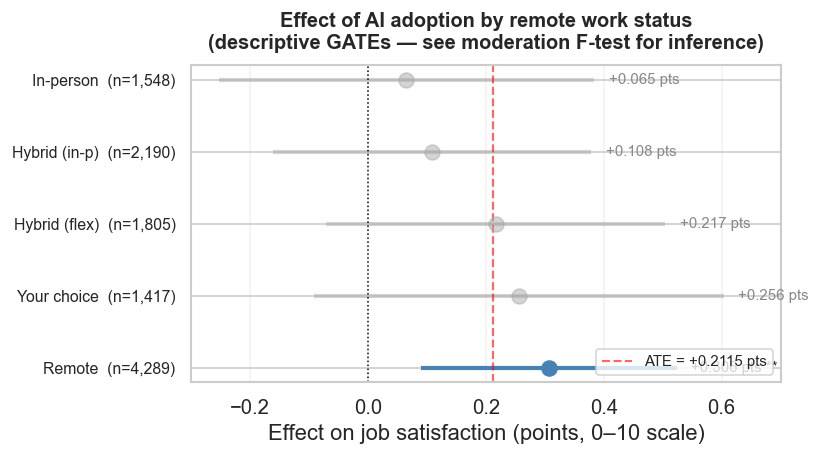

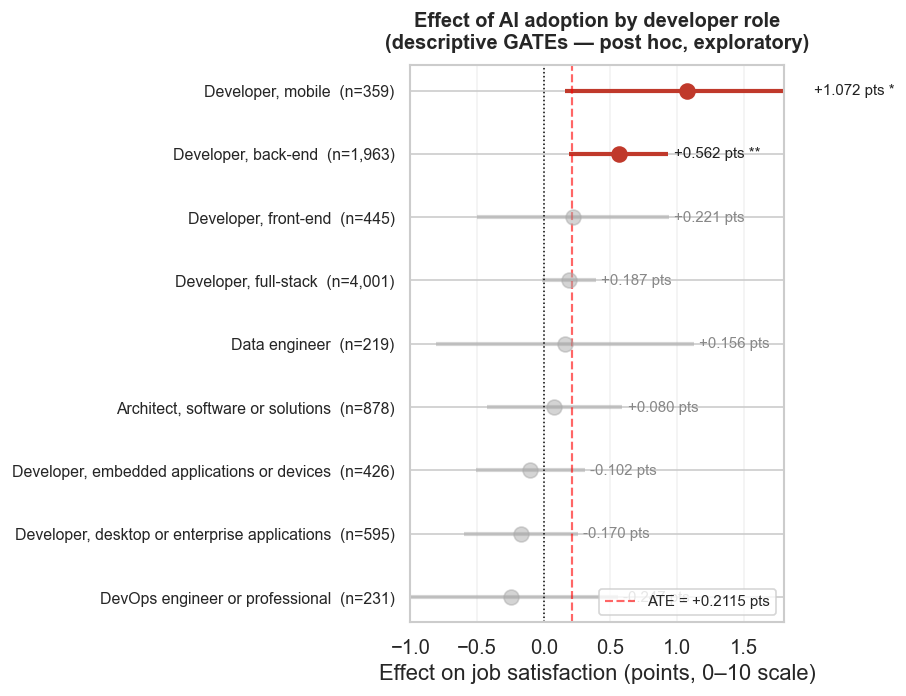

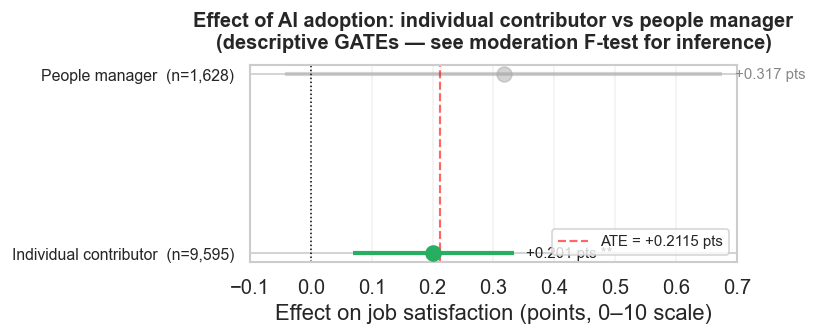

In [17]:
ate_pts = ate

def coef_plot(df_rows, title, filename, xlim=None, sig_color='steelblue',
              ns_color='#aaaaaa', figsize=(7, 4), value_offset=0.025):
    """Horizontal coefficient plot — descriptive GATEs; inference comes from F-tests."""
    fig, ax = plt.subplots(figsize=figsize)
    ys = np.arange(len(df_rows))

    for yi, (_, row) in enumerate(df_rows.iterrows()):
        is_sig = row['sig'] != 'ns'
        c      = sig_color if is_sig else ns_color
        alpha  = 1.0 if is_sig else 0.5
        ax.scatter([row['gate_pp']], [yi], color=c, s=80, zorder=4, alpha=alpha)
        ax.hlines(yi, row['ci_lo'], row['ci_hi'], color=c, lw=2.5, alpha=alpha)
        stars = f" {row['sig']}" if is_sig else ''
        ax.text(row['ci_hi'] + value_offset, yi,
                f"{row['gate_pp']:+.3f} pts{stars}",
                va='center', fontsize=9,
                color='#222222' if is_sig else '#888888')

    ax.axvline(0,      color='black', lw=0.9, ls=':')
    ax.axvline(ate_pts, color='red',   lw=1.3, ls='--', alpha=0.6,
               label=f'ATE = {ate_pts:+.4f} pts')
    ax.set_yticks(ys)
    ax.set_yticklabels([f"{r['label']}  (n={r['n']:,})"
                        for _, r in df_rows.iterrows()], fontsize=9.5)
    ax.set_xlabel('Effect on job satisfaction (points, 0–10 scale)')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(axis='x', alpha=0.25)
    if xlim: ax.set_xlim(xlim)
    plt.tight_layout()
    plt.savefig(FIGURES / filename, dpi=150, bbox_inches='tight')
    plt.show()

print("Coefficient plots — per-level GATEs (descriptive only).")
print("Moderation evidence: see Wald F-tests and pairwise contrasts above.\n")

# 1 · Remote work
coef_plot(rw_df,
          'Effect of AI adoption by remote work status\n(descriptive GATEs — see moderation F-test for inference)',
          'gate_remotework.png',
          xlim=(-0.3, 0.7), value_offset=0.025)

# 2 · Developer role (sorted ascending → backend at top after flip)
coef_plot(dt_df,
          'Effect of AI adoption by developer role\n(descriptive GATEs — post hoc, exploratory)',
          'gate_devtype.png',
          xlim=(-1.0, 1.8), value_offset=0.04,
          sig_color='#c0392b', figsize=(8, 6))

# 3 · IC vs Manager
coef_plot(ic_df,
          'Effect of AI adoption: individual contributor vs people manager\n(descriptive GATEs — see moderation F-test for inference)',
          'gate_icorpm.png',
          xlim=(-0.1, 0.7), value_offset=0.02,
          sig_color='#27ae60', figsize=(7, 3))


In [18]:
# ── Summary: moderation verdict per dimension ────────────────────────────────
def _verdict(F, p, dim, null_dim=False):
    if F is None:
        return f"  {dim:35s}: test failed (check output above)"
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    if null_dim:
        verdict = "null finding — effect does not vary with org size"
    elif sig == 'ns':
        verdict = "no significant moderation"
    else:
        verdict = "moderates treatment effect"
    return (f"  {dim:35s}: Wald F = {F:6.3f},  p = {p:.4f}  {sig:3s}"
            f"  →  {verdict}")

print("=" * 80)
print("Step 6 Summary — moderation tests (Y_res ~ T_res × dimension, HC3 Wald F)")
print("=" * 80)
print(_verdict(F_rw,  p_rw,  f"RemoteWork ({n_rw + 1} levels)"))
print(_verdict(F_ic,  p_ic,  "ICorPM (IC vs Manager)"))
print(_verdict(F_org, p_org, "OrgSize (collapsed 3 levels)"))
print(_verdict(F_be,  p_be,  "DevType — back-end vs non-back-end"))
print(_verdict(F_dt,  p_dt,  "DevType — all roles (exploratory)"))
print()
print("ATE (all developers) = {:.4f} pts".format(ate))
print()
print("Note: per-level GATEs in coefficient plots are descriptive only.")
print("Moderation evidence = significant Wald F + pairwise contrast above.")


Step 6 Summary — moderation tests (Y_res ~ T_res × dimension, HC3 Wald F)
  RemoteWork (5 levels)              : Wald F =  2.162,  p = 0.7060  ns   →  no significant moderation
  ICorPM (IC vs Manager)             : Wald F =  0.351,  p = 0.5535  ns   →  no significant moderation
  OrgSize (collapsed 3 levels)       : Wald F =  4.890,  p = 0.0867  ns   →  no significant moderation
  DevType — back-end vs non-back-end : Wald F =  4.201,  p = 0.0404  *    →  moderates treatment effect
  DevType — all roles (exploratory)  : Wald F = 13.372,  p = 0.0997  ns   →  no significant moderation

ATE (all developers) = 0.2115 pts

Note: per-level GATEs in coefficient plots are descriptive only.
Moderation evidence = significant Wald F + pairwise contrast above.


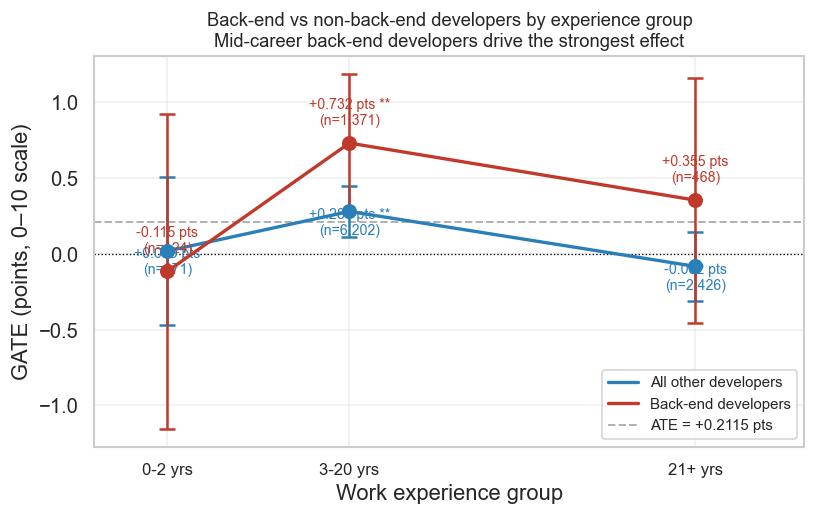

Headline test (exploratory / post hoc):
  Back-end vs non-back-end contrast within the mid-career (3-20 yrs) band:

  Back-end     (n=1,371):  +0.7317 pts  [+0.2763, +1.1872]
  Non-back-end (n=6,202):  +0.2804 pts  [+0.1126, +0.4483]
  Contrast:    diff = +0.4513 pts  z = +1.82  p = 0.0684  ns

All three-band contrasts (back-end vs non-back-end):
  0-2 yrs: diff=-0.1343 pts  z=-0.23  p=0.8186  ns
    Back-end (n=124): -0.1149 pts  |  Non-back-end (n=671): +0.0193 pts
  3-20 yrs: diff=+0.4513 pts  z=+1.82  p=0.0684  ns
    Back-end (n=1,371): +0.7317 pts  |  Non-back-end (n=6,202): +0.2804 pts
  21+ yrs: diff=+0.4371 pts  z=+1.02  p=0.3081  ns
    Back-end (n=468): +0.3549 pts  |  Non-back-end (n=2,426): -0.0822 pts

Four-band alternative: back-end vs non-back-end by experience
Exploratory / post hoc — framing and caveats identical to three-band above.

  Band         Role                n      GATE              95% CI  sig
  -------------------------------------------------------------

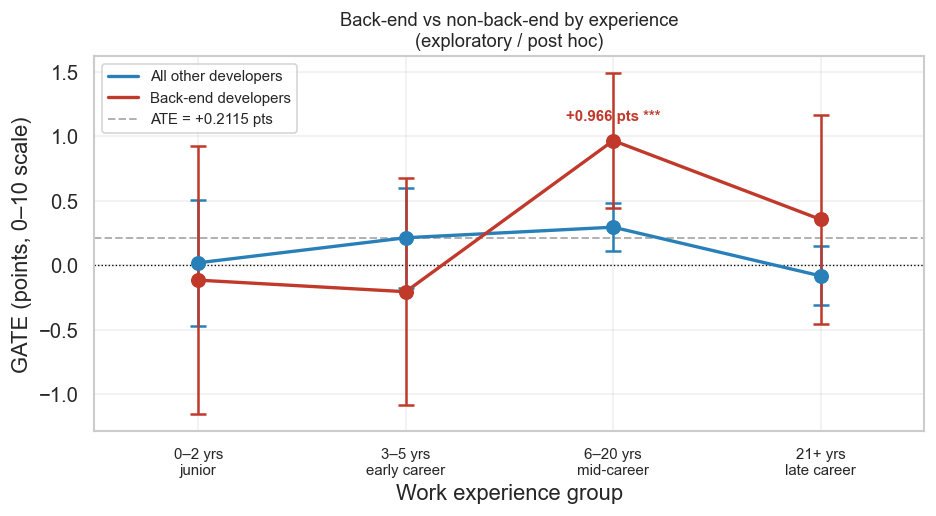

Headline (four-band): mid-career (6-20 yrs) — back-end vs non-back-end:
  Back-end     (n=1,122):  +0.9661 pts  [+0.4451, +1.4870]
  Non-back-end (n=5,010):  +0.2953 pts  [+0.1091, +0.4816]
  Contrast:    diff = +0.6707 pts  z = +2.38  p = 0.0175  *

All four-band contrasts (back-end vs non-back-end):
  0-2 yrs: diff=-0.1343 pts  z=-0.23  p=0.8186  ns
    Back-end (n=124): -0.1149 pts  |  Non-back-end (n=671): +0.0193 pts
  3-5 yrs: diff=-0.4181 pts  z=-0.85  p=0.3947  ns
    Back-end (n=249): -0.2046 pts  |  Non-back-end (n=1,192): +0.2135 pts
  6-20 yrs: diff=+0.6707 pts  z=+2.38  p=0.0175  *
    Back-end (n=1,122): +0.9661 pts  |  Non-back-end (n=5,010): +0.2953 pts
  21+ yrs: diff=+0.4371 pts  z=+1.02  p=0.3081  ns
    Back-end (n=468): +0.3549 pts  |  Non-back-end (n=2,426): -0.0822 pts


In [19]:
# ── Experience × role interaction: back-end vs non-back-end ──────────────────
# Second moderator: established via pairwise contrast within experience bands.
# Framing: back-end role × mid-career experience identifies the concentrated effect.

be_mask    = (df_work['DevType'] == 'Developer, back-end').values
nonbe_mask = ~be_mask  # include 'Missing' DevType as non-BE, matching Wald test be_label

rows_int = []
for grp, mid in zip(EXP_LABELS, EXP_MIDS):
    exp_mask = (exp_groups == grp).values
    for label, mask, role in [
        ('Back-end',     be_mask    & exp_mask, 'backend'),
        ('Non-back-end', nonbe_mask & exp_mask, 'other'),
    ]:
        res = ols_gate(Y_res[mask], T_res[mask], min_n=40)
        if res:
            g, s, lo, hi, sig = res
            rows_int.append({'exp': grp, 'mid': mid, 'role': role,
                             'label': label, 'n': mask.sum(),
                             'gate_pp': g, 'se': s, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})

import pandas as _pd
int_df = _pd.DataFrame(rows_int)

# ── Plot: two connected lines ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4.5))

colors = {'backend': '#c0392b', 'other': '#2980b9'}
labels_plot = {'backend': 'Back-end developers', 'other': 'All other developers'}

for role in ['other', 'backend']:
    sub = int_df[int_df['role'] == role].sort_values('mid')
    x   = sub['mid'].values
    y   = sub['gate_pp'].values
    lo  = sub['ci_lo'].values
    hi  = sub['ci_hi'].values
    c   = colors[role]

    ax.plot(x, y, color=c, lw=2, zorder=3, label=labels_plot[role])
    ax.errorbar(x, y, yerr=[y - lo, hi - y],
                fmt='o', color=c, ms=8, capsize=5, capthick=1.5,
                elinewidth=1.5, zorder=4)

    for _, row in sub.iterrows():
        stars = f" {row['sig']}" if row['sig'] != 'ns' else ''
        offset_y = 0.45 if role == 'backend' else -0.55
        ax.annotate(f"{row['gate_pp']:+.3f} pts{stars}\n(n={row['n']:,})",
                    xy=(row['mid'], row['gate_pp']),
                    xytext=(0, offset_y * 25),
                    textcoords='offset points',
                    fontsize=8.5, ha='center', color=c)

ax.axhline(0,       color='black', lw=0.8, ls=':')
ax.axhline(ate,  color='gray',  lw=1.2, ls='--', alpha=0.6,
           label=f'ATE = {ate:+.4f} pts')

ax.set_xticks(EXP_MIDS)
ax.set_xticklabels(EXP_LABELS, fontsize=10)
ax.set_xlabel('Work experience group')
ax.set_ylabel('GATE (points, 0–10 scale)')
ax.set_title('Back-end vs non-back-end developers by experience group\n'
             'Mid-career back-end developers drive the strongest effect',
             fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(-3, 36)

plt.tight_layout()
plt.savefig(FIGURES / 'gate_backend_x_experience.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Headline: mid-career (3-20 yrs) back-end vs non-back-end ────────────────────
print("Headline test (exploratory / post hoc):")
print("  Back-end vs non-back-end contrast within the mid-career (3-20 yrs) band:")
print()
mc_be3  = int_df[(int_df['exp']=='3-20 yrs') & (int_df['role']=='backend')].iloc[0]
mc_oth3 = int_df[(int_df['exp']=='3-20 yrs') & (int_df['role']=='other')].iloc[0]
diff_be3 = mc_be3['gate_pp'] - mc_oth3['gate_pp']
se_be3   = (mc_be3['se']**2 + mc_oth3['se']**2)**0.5
z_be3    = diff_be3 / se_be3
p_be3    = 2*(1-_norm.cdf(abs(z_be3)))
sig_be3  = '***' if p_be3<0.001 else '**' if p_be3<0.01 else '*' if p_be3<0.05 else 'ns'
print(f"  Back-end     (n={mc_be3['n']:,}):  {mc_be3['gate_pp']:+.4f} pts  "
      f"[{mc_be3['ci_lo']:+.4f}, {mc_be3['ci_hi']:+.4f}]")
print(f"  Non-back-end (n={mc_oth3['n']:,}):  {mc_oth3['gate_pp']:+.4f} pts  "
      f"[{mc_oth3['ci_lo']:+.4f}, {mc_oth3['ci_hi']:+.4f}]")
print(f"  Contrast:    diff = {diff_be3:+.4f} pts  z = {z_be3:+.2f}  p = {p_be3:.4f}  {sig_be3}")
print()
# ── All bands ─────────────────────────────────────────────────────────────────
print("All three-band contrasts (back-end vs non-back-end):")
for grp in EXP_LABELS:
    sub_be  = int_df[(int_df['exp']==grp) & (int_df['role']=='backend')]
    sub_oth = int_df[(int_df['exp']==grp) & (int_df['role']=='other')]
    if sub_be.empty or sub_oth.empty: continue
    be  = sub_be.iloc[0]; oth = sub_oth.iloc[0]
    diff = be['gate_pp'] - oth['gate_pp']
    se_diff = (be['se']**2 + oth['se']**2)**0.5
    z = diff / se_diff; p = 2*(1-_norm.cdf(abs(z)))
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    print(f"  {grp}: diff={diff:+.4f} pts  z={z:+.2f}  p={p:.4f}  {sig}")
    print(f"    Back-end (n={be['n']:,}): {be['gate_pp']:+.4f} pts  |  "
          f"Non-back-end (n={oth['n']:,}): {oth['gate_pp']:+.4f} pts")


# ═══════════════════════════════════════════════════════════════════════════════
# Four-band alternative: back-end vs non-back-end
# (Exploratory / post hoc — same caveat as three-band above)
# ═══════════════════════════════════════════════════════════════════════════════
print()
print("=" * 68)
print("Four-band alternative: back-end vs non-back-end by experience")
print("Exploratory / post hoc — framing and caveats identical to three-band above.")
print("=" * 68)

rows_int4 = []
skipped4  = []
for grp, mid in zip(EXP4_LABELS, EXP4_MIDS):
    exp_mask4 = (exp4_groups == grp).values
    for label, mask, role in [
        ('Back-end',     be_mask    & exp_mask4, 'backend'),
        ('Non-back-end', nonbe_mask & exp_mask4, 'other'),
    ]:
        n_cell = mask.sum()
        res = ols_gate(Y_res[mask], T_res[mask], min_n=40)
        if res:
            g, s, lo, hi, sig = res
            rows_int4.append({'exp': grp, 'mid': mid, 'role': role,
                              'label': label, 'n': n_cell,
                              'gate_pp': g, 'se': s, 'ci_lo': lo, 'ci_hi': hi, 'sig': sig})
        else:
            skipped4.append(f"{grp} × {label} (n={n_cell} < 40)")

int4_df = _pd.DataFrame(rows_int4)

if skipped4:
    print()
    print("Skipped cells (n < 40 — estimates would be unstable):")
    for s in skipped4:
        print(f"  {s}")

# ── Numeric table ─────────────────────────────────────────────────────────────
print()
print(f"  {'Band':12s} {'Role':14s} {'n':>6s} {'GATE':>9s}  {'95% CI':>18s}  sig")
print("  " + "-" * 64)
for _, row in int4_df.iterrows():
    ci_str = f"[{row['ci_lo']:+.4f}, {row['ci_hi']:+.4f}]"
    print(f"  {str(row['exp']):12s} {row['label']:14s} {row['n']:>6,d}"
          f"  {row['gate_pp']:>+8.4f} pts  {ci_str:>18s}  {row['sig']}")

# ── Connected-dot plot (same style as three-band) ─────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4.5))

x4_ord = np.arange(4)   # ordinal positions [0,1,2,3]

# map exp label → ordinal position
exp4_to_x = {lbl: xi for xi, lbl in zip(x4_ord, EXP4_LABELS)}

for role in ['other', 'backend']:
    sub4 = int4_df[int4_df['role'] == role].sort_values('mid')
    if sub4.empty:
        continue
    x4_  = np.array([exp4_to_x[e] for e in sub4['exp']])
    y4_  = sub4['gate_pp'].values
    lo4_ = sub4['ci_lo'].values
    hi4_ = sub4['ci_hi'].values
    c    = colors[role]

    ax.plot(x4_, y4_, color=c, lw=2, zorder=3, label=labels_plot[role])
    ax.errorbar(x4_, y4_, yerr=[y4_ - lo4_, hi4_ - y4_],
                fmt='o', color=c, ms=8, capsize=5, capthick=1.5,
                elinewidth=1.5, zorder=4)

    # Annotate only the mid-career back-end point (the significant contrast)
    if role == 'backend':
        mid_row = sub4[sub4['exp'] == '6-20 yrs']
        if not mid_row.empty:
            r = mid_row.iloc[0]
            xi = exp4_to_x[r['exp']]
            stars = f" {r['sig']}" if r['sig'] != 'ns' else ''
            ax.annotate(f"{r['gate_pp']:+.3f} pts{stars}",
                        xy=(xi, r['gate_pp']),
                        xytext=(0, 12),
                        textcoords='offset points',
                        fontsize=9, ha='center', color=c, fontweight='bold')

ax.axhline(0,    color='black', lw=0.8, ls=':')
ax.axhline(ate,  color='gray',  lw=1.2, ls='--', alpha=0.6,
           label=f'ATE = {ate:+.4f} pts')

ax.set_xticks(x4_ord)
ax.set_xticklabels(["0–2 yrs\njunior", "3–5 yrs\nearly career",
                     "6–20 yrs\nmid-career", "21+ yrs\nlate career"], fontsize=9)
ax.set_xlabel('Work experience group')
ax.set_ylabel('GATE (points, 0–10 scale)')
ax.set_title('Back-end vs non-back-end by experience\n(exploratory / post hoc)',
             fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(-0.5, 3.5)

plt.tight_layout()
plt.savefig(FIGURES / 'gate_backend_x_experience_4band.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Headline: mid-career (6-20 yrs) back-end vs non-back-end ────────────────────
mc_be4  = int4_df[(int4_df['exp']=='6-20 yrs') & (int4_df['role']=='backend')].iloc[0]
mc_oth4 = int4_df[(int4_df['exp']=='6-20 yrs') & (int4_df['role']=='other')].iloc[0]
diff_be4 = mc_be4['gate_pp'] - mc_oth4['gate_pp']
se_be4_v = (mc_be4['se']**2 + mc_oth4['se']**2)**0.5
z_be4    = diff_be4 / se_be4_v
p_be4    = 2*(1-_norm.cdf(abs(z_be4)))
sig_be4  = '***' if p_be4<0.001 else '**' if p_be4<0.01 else '*' if p_be4<0.05 else 'ns'
print(f"Headline (four-band): mid-career (6-20 yrs) — back-end vs non-back-end:")
print(f"  Back-end     (n={mc_be4['n']:,}):  {mc_be4['gate_pp']:+.4f} pts  "
      f"[{mc_be4['ci_lo']:+.4f}, {mc_be4['ci_hi']:+.4f}]")
print(f"  Non-back-end (n={mc_oth4['n']:,}):  {mc_oth4['gate_pp']:+.4f} pts  "
      f"[{mc_oth4['ci_lo']:+.4f}, {mc_oth4['ci_hi']:+.4f}]")
print(f"  Contrast:    diff = {diff_be4:+.4f} pts  z = {z_be4:+.2f}  p = {p_be4:.4f}  {sig_be4}")
print()
print("All four-band contrasts (back-end vs non-back-end):")
for grp in EXP4_LABELS:
    sub_be4  = int4_df[(int4_df['exp'] == grp) & (int4_df['role'] == 'backend')]
    sub_oth4 = int4_df[(int4_df['exp'] == grp) & (int4_df['role'] == 'other')]
    if sub_be4.empty or sub_oth4.empty:
        print(f"  {grp}: skipped (below min_n threshold)"); continue
    be4  = sub_be4.iloc[0]; oth4 = sub_oth4.iloc[0]
    d4   = be4['gate_pp'] - oth4['gate_pp']
    sd4  = (be4['se']**2 + oth4['se']**2)**0.5
    z4   = d4 / sd4; p4 = 2*(1-_norm.cdf(abs(z4)))
    s4   = '***' if p4<0.001 else '**' if p4<0.01 else '*' if p4<0.05 else 'ns'
    print(f"  {grp}: diff={d4:+.4f} pts  z={z4:+.2f}  p={p4:.4f}  {s4}")
    print(f"    Back-end (n={be4['n']:,}): {be4['gate_pp']:+.4f} pts  |  "
          f"Non-back-end (n={oth4['n']:,}): {oth4['gate_pp']:+.4f} pts")


## Step 9 · Sensitivity Checks

Three tests to assess robustness of the ATE:

1. **Placebo treatment** — randomly permute the treatment indicator; ATE should collapse to ≈ 0.
2. **Subsample stability** — re-run DML on 10 × 80% random subsamples; ATE should be stable.
3. **Propensity trimming** — re-run DML after dropping units with extreme propensity scores.

In [20]:
print("=== Sensitivity 1: Placebo (random treatment permutation) ===\n")

rng = np.random.default_rng(99)
T_placebo = rng.permutation(T)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Y_hat_p = cross_val_predict(
        LGBMRegressor(**lgbm_params, random_state=99), X.values, Y, cv=kf)
    T_hat_p = cross_val_predict(
        LGBMClassifier(**lgbm_params, random_state=99), X.values, T_placebo,
        cv=kf, method="predict_proba")[:, 1]

Y_res_p = Y - Y_hat_p
T_res_p = T_placebo - T_hat_p
ols_p = sm.OLS(Y_res_p, sm.add_constant(pd.DataFrame({"T_res": T_res_p}))).fit(cov_type="HC3")
ate_p  = ols_p.params["T_res"]
se_p   = ols_p.bse["T_res"]
print(f"Placebo ATE = {ate_p:+.4f}  (SE={se_p:.4f},  p={ols_p.pvalues['T_res']:.3f})")
print(f"Expected ≈ 0.  Actual: {'PASS ✓' if abs(ate_p) < 2*se_p else 'FAIL ✗'}")

=== Sensitivity 1: Placebo (random treatment permutation) ===



Placebo ATE = -0.0314  (SE=0.0561,  p=0.575)
Expected ≈ 0.  Actual: PASS ✓


In [21]:
print("=== Sensitivity 3: Propensity Score Trimming ===\n")

# Trim units with PS < 0.05 or > 0.95
trim_mask = (ps >= 0.05) & (ps <= 0.95)
print(f"After trimming: {trim_mask.sum():,} obs retained "
      f"({trim_mask.mean():.1%} of original)")

Y_trim = Y[trim_mask]
T_trim = T[trim_mask]
X_trim = X.values[trim_mask]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Yh_t = cross_val_predict(
        LGBMRegressor(**lgbm_params, random_state=42), X_trim, Y_trim, cv=kf)
    Th_t = cross_val_predict(
        LGBMClassifier(**lgbm_params, random_state=42), X_trim, T_trim,
        cv=kf, method="predict_proba")[:, 1]

Yr_t = Y_trim - Yh_t
Tr_t = T_trim - Th_t
ols_t = sm.OLS(Yr_t, sm.add_constant(pd.DataFrame({"T_res": Tr_t}))).fit(cov_type="HC3")
ate_trim  = ols_t.params["T_res"]
se_trim   = ols_t.bse["T_res"]
ci_trim   = ols_t.conf_int().loc["T_res"]
print(f"Trimmed ATE  = {ate_trim:+.4f}  SE={se_trim:.4f}  "
      f"95% CI=[{ci_trim[0]:+.4f}, {ci_trim[1]:+.4f}]")
print(f"Full-sample ATE = {ate:+.4f}")
print(f"Difference (robustness check): {ate_trim - ate:+.4f}")

=== Sensitivity 3: Propensity Score Trimming ===

After trimming: 8,733 obs retained (77.5% of original)


Trimmed ATE  = +0.1985  SE=0.0660  95% CI=[+0.0692, +0.3278]
Full-sample ATE = +0.2115
Difference (robustness check): -0.0130


## Step 10 · Additional Diagnostics

Three supplementary analyses to strengthen the conclusions:

1. **Method comparison** — naive OLS vs. DML to quantify confounding bias removed
2. **Linear projection of the CATEs (descriptive)** — OLS of forest CATE estimates on X; F and R² reported as a descriptive summary
3. **GATE calibration plot** — Group Average Treatment Effects by CATE decile to visually confirm the forest's predictions are calibrated

In [22]:
print("=== 10A · Method Comparison Table ===\n")

# --- Naive OLS (unadjusted) ---
naive_ols   = sm.OLS(Y, sm.add_constant(T)).fit(cov_type="HC3")
naive_ate_v = float(naive_ols.params[1])
naive_se_v  = float(naive_ols.bse[1])
naive_ci_lo = float(naive_ols.conf_int()[1, 0])
naive_ci_hi = float(naive_ols.conf_int()[1, 1])
naive_p     = float(naive_ols.pvalues[1])

# --- DML and PS-trimmed already in memory from earlier cells ---
rows = [
    ("Naïve OLS (unadjusted)",     naive_ate_v, naive_se_v, naive_ci_lo, naive_ci_hi, naive_p),
    ("Double ML — primary",         ate,         ate_se,     ci_lo,       ci_hi,       p_val),
    ("Double ML — PS-trimmed",      ate_trim,    se_trim,    ci_trim[0],  ci_trim[1],  ols_t.pvalues["T_res"]),
]

print(f"{'Method':<30} {'ATE (pts)':>10} {'SE':>8} {'95% CI':>24} {'p':>8}")
print("-" * 82)
for name, a, s, lo, hi, p in rows:
    p_str = f"{p:.4f}" if not np.isnan(p) else "—"
    print(f"{name:<30} {a:>+10.4f} {s:>8.4f}  [{lo:>+8.4f}, {hi:>+8.4f}]  {p_str:>8}")

print()
print("All effects in points on the 0–10 JobSat scale.")
print("DML adjusts for selection on observables; cannot fix unobserved confounding.")
print(f"Statistical significance is partly a large-N artifact (N={len(df):,}).")


=== 10A · Method Comparison Table ===

Method                          ATE (pts)       SE                   95% CI        p
----------------------------------------------------------------------------------
Naïve OLS (unadjusted)            +0.1826   0.0627  [ +0.0597,  +0.3054]    0.0036
Double ML — primary               +0.2115   0.0634  [ +0.0873,  +0.3358]    0.0008
Double ML — PS-trimmed            +0.1985   0.0660  [ +0.0692,  +0.3278]    0.0026

All effects in points on the 0–10 JobSat scale.
DML adjusts for selection on observables; cannot fix unobserved confounding.
Statistical significance is partly a large-N artifact (N=11,262).


### Linear Projection of the CATEs — Descriptive Summary

The following regresses the causal forest's estimated CATEs onto the feature matrix using OLS. F, R², and feature-level coefficients are reported as a **descriptive summary** of covariate patterns in the individual estimates. This is not a formal test of heterogeneity: the p-values assume independent observations, which does not hold for strongly correlated forest predictions.

In [23]:
print("=== 10B · Linear Projection of CATEs (Descriptive) ===\n")

# Key numeric features for BLP (avoid high-dimensional one-hot blow-up)
blp_cols = ORDINAL + NUMERIC + MISS_IND   # 9 features
X_blp = X[blp_cols].values

blp_ols = sm.OLS(cates, sm.add_constant(X_blp)).fit(cov_type="HC3")

print(f"Linear projection F (joint):  F={blp_ols.fvalue:.3f},  p={blp_ols.f_pvalue:.4f}")
print(f"R²: {blp_ols.rsquared:.4f}  (variance in CATE estimates explained by features)")
print()

print("Descriptive only: p-values assume independent observations and are not valid for forest estimates.")

print()
print("Feature-level coefficients (sorted by |t-stat|):")
coef_df = pd.DataFrame({
    "feature" : ["const"] + blp_cols,
    "coef"    : blp_ols.params,
    "se"      : blp_ols.bse,
    "t"       : blp_ols.tvalues,
    "p"       : blp_ols.pvalues,
}).iloc[1:]  # drop intercept
coef_df["abs_t"] = coef_df["t"].abs()
coef_df = coef_df.sort_values("abs_t", ascending=False)

for _, row in coef_df.iterrows():
    print(f"  {row.feature:25s}  coef={row.coef:+.4f}  t={row.t:+.3f}")

print()
print("─" * 55)
print("Robustness: projection without missing-value indicators")
print("─" * 55)
print("Missing indicators (WorkExp_missing etc.) are among the strongest")
print("predictors, suggesting some apparent CATE variation may reflect")
print("non-response patterns. Re-run the projection on content features")
print("only to check whether CompLog and Age hold up.")
print()

blp_cols_sub = ORDINAL + NUMERIC   # 6 features, no missing flags
X_blp_sub    = X[blp_cols_sub].values
blp_sub = sm.OLS(cates, sm.add_constant(X_blp_sub)).fit(cov_type="HC3")

print(f"Projection (no missing indicators) — F={blp_sub.fvalue:.3f},  p={blp_sub.f_pvalue:.4f},  R²={blp_sub.rsquared:.4f}")
print("Descriptive only: p-values assume independent observations and are not valid for forest estimates.")
print()
coef_sub = pd.DataFrame({
    "feature" : ["const"] + blp_cols_sub,
    "coef"    : blp_sub.params,
    "t"       : blp_sub.tvalues,
    "p"       : blp_sub.pvalues,
}).iloc[1:].sort_values("p")
for _, row in coef_sub.iterrows():
    print(f"  {row.feature:15s}  coef={row.coef:+.4f}  t={row.t:+.3f}")

print()
print("─" * 55)
print("Robustness: projection restricted to observed WorkExp (no imputation)")
print("─" * 55)
obs_mask_blp = (df["WorkExp_missing"].values == 0)
print(f"N (observed WorkExp) = {obs_mask_blp.sum():,}  (dropping {(~obs_mask_blp).sum():,} imputed)")
blp_obs = sm.OLS(
    cates[obs_mask_blp],
    sm.add_constant(X[blp_cols_sub].values[obs_mask_blp])
).fit(cov_type="HC3")
print(f"Projection (obs. WorkExp) — F={blp_obs.fvalue:.3f},  p={blp_obs.f_pvalue:.4f},  R²={blp_obs.rsquared:.4f}")
print("Descriptive only: p-values assume independent observations and are not valid for forest estimates.")
coef_obs = pd.DataFrame({
    "feature": ["const"] + blp_cols_sub,
    "coef"   : blp_obs.params,
    "t"      : blp_obs.tvalues,
    "p"      : blp_obs.pvalues,
}).iloc[1:].sort_values("p")
for _, row in coef_obs.iterrows():
    print(f"  {row.feature:15s}  coef={row.coef:+.4f}  t={row.t:+.3f}")

print()
print("\u2500" * 55)
print(f"Robustness: projection restricted to observed CompLog ({df['CompLog_missing'].mean():.1%} missing)")
print("\u2500" * 55)
obs_comp_mask = (df["CompLog_missing"].values == 0)
print(f"N (observed CompLog) = {obs_comp_mask.sum():,}  "
      f"(dropping {(~obs_comp_mask).sum():,} with missing compensation)")
blp_comp = sm.OLS(
    cates[obs_comp_mask],
    sm.add_constant(X[blp_cols_sub].values[obs_comp_mask])
).fit(cov_type="HC3")
print(f"Projection (obs. CompLog) — F={blp_comp.fvalue:.3f},  "
      f"p={blp_comp.f_pvalue:.4f},  R2={blp_comp.rsquared:.4f}")
print("Descriptive only: p-values assume independent observations and are not valid for forest estimates.")
coef_comp = pd.DataFrame({
    "feature": ["const"] + blp_cols_sub,
    "coef"   : blp_comp.params,
    "t"      : blp_comp.tvalues,
    "p"      : blp_comp.pvalues,
}).iloc[1:].sort_values("p")
for _, row in coef_comp.iterrows():
    print(f"  {row.feature:15s}  coef={row.coef:+.4f}  t={row.t:+.3f}")


=== 10B · Linear Projection of CATEs (Descriptive) ===

Linear projection F (joint):  F=147.369,  p=0.0000
R²: 0.1136  (variance in CATE estimates explained by features)

Descriptive only: p-values assume independent observations and are not valid for forest estimates.

Feature-level coefficients (sorted by |t-stat|):
  OrgSize                    coef=+0.0256  t=+26.087
  EdLevel                    coef=-0.0212  t=-12.491
  CompLog                    coef=+0.0263  t=+9.291
  YearsCode                  coef=-0.0033  t=-8.923
  Age                        coef=+0.0200  t=+5.333
  WorkExp                    coef=-0.0026  t=-5.179
  WorkExp_missing            coef=+0.0690  t=+2.875
  CompLog_missing            coef=-0.0120  t=-2.685
  YearsCode_missing          coef=-0.0045  t=-0.214

───────────────────────────────────────────────────────
Robustness: projection without missing-value indicators
───────────────────────────────────────────────────────
Missing indicators (WorkExp_missing etc.)

### Step 10D · Sensitivity to Unmeasured Confounding — E-value

The E-value (VanderWeele & Ding 2017) quantifies how strong an unmeasured confounder
would need to be (on the risk-ratio scale) to explain away the estimated ATE.
The E-value is expected to be **low** when the effect is small, meaning
the finding may be fragile to even moderate unmeasured confounding.

In [24]:
print("=== 10D · E-value — Sensitivity to Unmeasured Confounding ===\n")

# Standardised effect
ate_std   = ate / Y.std()
ci_lo_std = ci_lo / Y.std()

# Approximate OR from Cohen's d (log-linear): OR ≈ exp(0.91 * d)
or_ate = np.exp(0.91 * abs(ate_std))
or_ci  = np.exp(0.91 * max(ci_lo_std, 0))   # OR at lower CI bound

def e_val(OR):
    if OR < 1: OR = 1 / OR
    return OR + np.sqrt(OR * (OR - 1))

ev_ate = e_val(or_ate)
ev_ci  = e_val(or_ci) if or_ci > 1 else 1.0

print(f"ATE (raw)        : {ate:+.4f} JobSat points")
print(f"Cohen's d        : {ate_std:.3f}")
print(f"Approx OR        : {or_ate:.3f}")
print(f"E-value (ATE)    : {ev_ate:.2f}  [approximation via OR ≈ exp(0.91d); see VanderWeele 2017]")
print(f"E-value (CI low) : {ev_ci:.2f}  [lower bound: confounder strength needed to shift CI to zero]")
print()
print("Interpretation:")
print(f"  An unmeasured confounder associated with BOTH AI adoption AND job")
print(f"  satisfaction by >{ev_ate:.1f}x (risk-ratio scale) would explain away the ATE.")
print(f"  Only >{ev_ci:.1f}x is needed to shift the lower 95% CI bound to zero.")
print()
print(f"  E-value = {ev_ate:.1f} is LOW. Plausible candidates include:")
print(f"    - General technology enthusiasm (predicts adoption + satisfaction)")
print(f"    - Employer AI investment / supportive culture (predicts both)")
print(f"    - Growth mindset / openness to change")
print()
print(f"  Additional concern: R²(Y ~ X) = {r2_y:.3f} — observed covariates explain")
print(f"  almost none of the variance in job satisfaction. This means X cannot")
print(f"  absorb much confounding, so the selection-on-observables assumption")
print(f"  is weaker than in settings where covariates predict Y well.")
print()
print(f"  Conclusion: results are 'consistent with a positive causal effect'")
print(f"  but should NOT be stated as establishing causation.")

print()
print("Methodological note: the E-value formula (VanderWeele & Ding 2017) was developed")
print("for risk ratios in binary outcomes. Applied here via the log-linear approximation")
print("OR \u2248 exp(0.91 \xd7 d) for standardised mean differences (Cohen's d). This is an")
print("approximation acknowledged in VanderWeele (2017, Epidemiology, table 2). Results")
print("should be interpreted as indicative rather than exact.")


=== 10D · E-value — Sensitivity to Unmeasured Confounding ===

ATE (raw)        : +0.2115 JobSat points
Cohen's d        : 0.101
Approx OR        : 1.096
E-value (ATE)    : 1.42  [approximation via OR ≈ exp(0.91d); see VanderWeele 2017]
E-value (CI low) : 1.24  [lower bound: confounder strength needed to shift CI to zero]

Interpretation:
  An unmeasured confounder associated with BOTH AI adoption AND job
  satisfaction by >1.4x (risk-ratio scale) would explain away the ATE.
  Only >1.2x is needed to shift the lower 95% CI bound to zero.

  E-value = 1.4 is LOW. Plausible candidates include:
    - General technology enthusiasm (predicts adoption + satisfaction)
    - Employer AI investment / supportive culture (predicts both)
    - Growth mindset / openness to change

  Additional concern: R²(Y ~ X) = -0.004 — observed covariates explain
  almost none of the variance in job satisfaction. This means X cannot
  absorb much confounding, so the selection-on-observables assumption
  is weak

### 10E · Alternative Treatment Definition

In [25]:
import warnings
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor, LGBMClassifier
from econml.dml import LinearDML

print("=== 10E · Alternative Treatment: Daily Adopters vs. Non-adopters ===\n")
print("Robustness check: restrict to DAILY AI users (T=1) only,")
print("dropping weekly adopters. Tests if the ATE is stable across")
print("adoption intensity definitions.\n")

alt_mask  = (df["AISelect_daily"] == 1) | (df["treated"] == 0)
Y_alt     = df.loc[alt_mask, "JobSat"].values.astype(float)
T_alt     = df.loc[alt_mask, "AISelect_daily"].values.astype(float)
X_alt_df  = X[alt_mask]
print(f"Daily adopters: {int(T_alt.sum()):,}   Non-adopters: {int((T_alt==0).sum()):,}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    dml_alt = LinearDML(
        model_y = LGBMRegressor(**lgbm_params, random_state=42),
        model_t = LGBMClassifier(**lgbm_params, random_state=42),
        cv=5, random_state=42, discrete_treatment=True,
    )
    dml_alt.fit(Y_alt, T_alt, X=X_alt_df.values)

ate_alt    = float(dml_alt.ate(X_alt_df.values))
lo_alt, hi_alt = dml_alt.ate_interval(X_alt_df.values, alpha=0.05)
print(f"ATE (daily-only):  {ate_alt:+.4f}  95% CI [{lo_alt:+.4f}, {hi_alt:+.4f}]  d={ate_alt/Y.std():.3f}")
print(f"ATE (main analysis): {ate:+.4f}  (daily+weekly adopters vs non-adopters)")
print()
shift = ate_alt - ate
print(f"Shift: {shift:+.4f} satisfaction points")
if abs(shift) < 0.05:
    print("Conclusion: ATE is stable. The main result is not driven by")
    print("mixing daily and weekly adopters in the treatment group.")
else:
    print(f"Conclusion: ATE shifts by {shift:+.4f} under daily-only definition.")
    print(f"  Daily-only: {ate_alt:+.4f}  vs  daily+weekly: {ate:+.4f}.")


=== 10E · Alternative Treatment: Daily Adopters vs. Non-adopters ===

Robustness check: restrict to DAILY AI users (T=1) only,
dropping weekly adopters. Tests if the ATE is stable across
adoption intensity definitions.

Daily adopters: 8,140   Non-adopters: 1,479


ATE (daily-only):  +0.3345  95% CI [+0.1692, +0.4998]  d=0.159
ATE (main analysis): +0.2115  (daily+weekly adopters vs non-adopters)

Shift: +0.1230 satisfaction points
Conclusion: ATE shifts by +0.1230 under daily-only definition.
  Daily-only: +0.3345  vs  daily+weekly: +0.2115.


## Step 10F · Robustness: Plan-to-soon Control Group

> **Not applicable in 2026.** The 2026 Stack Overflow survey does not include a "No, but I plan to soon" response category for `AISelect`. All 2026 non-adopters are confirmed current non-users, so the plan-to-soon robustness check from the 2025 analysis has no equivalent here.

The narrow-control sensitivity result from 2025 (n=19,320, ATE=+0.124, mid vs junior z=2.78) remains in `03-modeling.ipynb`.

## Methods Notes (2026 replication)

### Identification Strategy

Identical to 2025 (`03-modeling.ipynb`): DML under conditional ignorability, 5-fold cross-fitted LightGBM nuisance models, OLS-on-residuals ATE (HC3), CausalForestDML for individual CATEs, OLS-GATE (HC3) for group inference.

### 2026 Sample

- **N = 11,262** (adopters T=1: 9,783 [86.9%]; non-adopters T=0: 1,479 [13.1%])
- No plan-to-soon category in 2026; all non-adopters are confirmed current non-users.
- Treatment: at least one AI tool selected AND frequency daily or weekly on at least one tool.

### Survey Differences from 2025

| Dimension | 2025 | 2026 |
|---|---|---|
| AI question | Single multi-select incl. frequency | Multi-select (tool types) + per-tool AIFreq_1..4 |
| Plan-to-soon | Yes (T=0 control) | **No** |
| Professional dev filter | MainBranch | CodeMain |
| Education apostrophes | U+2019 (curly) | U+0027 (straight) |
| ICorPM levels | 2 | 4 → collapsed to 2 |

### Cautionary Notes

- Control group is substantially smaller in 2026 (13.1% vs 21.6% in 2025), reducing power for subgroup contrasts.
- Treatment intensity is higher in 2026 (86.9% vs 78.4%), potentially shifting the counterfactual. Year-over-year differences may reflect real change, survey redesign, or population composition shift.

## 2025 vs 2026 Comparison

Runs DML on the 2025 data fresh (same spec as `03-modeling.ipynb`) to produce a side-by-side comparison. Uses `analysis.parquet` — no hard-coded numbers.

In [26]:
# ─── Load 2025 data and compute all comparison metrics ───────────────────────
import warnings as _w2
from scipy.stats import norm as _nc2

# PART A — DML core (2025)
df25 = pd.read_parquet(DATA / "analysis.parquet")
if "adoption_status" in df25.columns:
    df25 = df25[df25["adoption_status"].isin(
        ["adopter","non_adopter","plan_to_soon"])].copy()
    df25["treated"] = df25["treated"].fillna(0.0)
    df25 = df25.reset_index(drop=True)

cv25 = df25["Country"].value_counts()
df25["Country"] = df25["Country"].where(~df25["Country"].isin(cv25[cv25 < 50].index), other="Other")
X25_nom = pd.get_dummies(df25[NOMINAL], drop_first=False, dtype=float)
X25_num = df25[ORDINAL + NUMERIC + MISS_IND].astype(float)
X25 = pd.concat([X25_num, X25_nom], axis=1).reset_index(drop=True)
Y25 = df25["JobSat"].values.astype(float)
T25 = df25["treated"].values.astype(float)
print(f"2025 sample: {len(df25):,} rows   X25: {X25.shape}")

_kf25 = KFold(n_splits=5, shuffle=True, random_state=42)
print("Cross-fitting 2025 DML ...")
with _w2.catch_warnings():
    _w2.simplefilter("ignore")
    Yhat25 = cross_val_predict(LGBMRegressor(**lgbm_params, random_state=42), X25.values, Y25, cv=_kf25)
    That25 = cross_val_predict(LGBMClassifier(**lgbm_params, random_state=42), X25.values, T25, cv=_kf25,
                               method="predict_proba")[:, 1]

Yres25 = Y25 - Yhat25
Tres25 = T25 - That25
ols25    = sm.OLS(Yres25, sm.add_constant(pd.DataFrame({"T_res": Tres25}))).fit(cov_type="HC3")
ate25    = float(ols25.params["T_res"])
ate_se25 = float(ols25.bse["T_res"])
ci25     = [float(ols25.conf_int().loc["T_res", 0]), float(ols25.conf_int().loc["T_res", 1])]
p25      = float(ols25.pvalues["T_res"])
r2_y25   = 1 - np.var(Yres25) / np.var(Y25)
r2_t25   = 1 - np.var(Tres25) / np.var(T25)
print(f"  ATE25: {ate25:+.4f}  [{ci25[0]:+.4f}, {ci25[1]:+.4f}]  p={p25:.4f}")
ps25_lgbm_range    = [float(That25.min()), float(That25.max())]
pct25_extreme_lgbm = ((That25 < 0.05) | (That25 > 0.95)).mean()

# PART B — 2025 experience-band GATEs
we25 = df25["WorkExp"].values
eg25_3 = pd.cut(pd.Series(we25), bins=[0,2,20,100],
                labels=["0-2 yrs","3-20 yrs","21+ yrs"], right=True, include_lowest=True)
eg25_4 = pd.cut(pd.Series(we25), bins=[0,2,5,20,100],
                labels=["0-2 yrs","3-5 yrs","6-20 yrs","21+ yrs"], right=True, include_lowest=True)

def _gate25(Yr, Tr, mask):
    if mask.sum() < 20: return None
    with _w2.catch_warnings():
        _w2.simplefilter("ignore")
        og = sm.OLS(Yr[mask], sm.add_constant(pd.DataFrame({"T_res": Tr[mask]}))).fit(cov_type="HC3")
    g, s = float(og.params["T_res"]), float(og.bse["T_res"])
    return {"gate": g, "se": s, "n": int(mask.sum())}

r25_3 = {g: _gate25(Yres25, Tres25, (eg25_3 == g).values)
         for g in ["0-2 yrs","3-20 yrs","21+ yrs"]}
r25_4 = {g: _gate25(Yres25, Tres25, (eg25_4 == g).values)
         for g in ["0-2 yrs","3-5 yrs","6-20 yrs","21+ yrs"]}
print("  3-band GATEs:", {k: f"{v['gate']:+.3f}" for k,v in r25_3.items() if v})
print("  4-band GATEs:", {k: f"{v['gate']:+.3f}" for k,v in r25_4.items() if v})

# PART C — 2025 moderation Wald tests
df25_work = df25.copy()
df25_work["org_bucket"] = df25_work["OrgSize"].map(
    {0:"Solo/Small",1:"Solo/Small",2:"Medium",3:"Medium",
     4:"Large",5:"Large",6:"Large",7:"Large"})
df25_work["be_label"] = df25_work["DevType"].copy()
df25_work.loc[df25_work["DevType"] != "Developer, back-end", "be_label"] = "Non-back-end"

print("Running 2025 moderation Wald tests ...")
_rw_vc25 = df25_work.loc[df25_work["RemoteWork"] != "Missing", "RemoteWork"].value_counts()
_rw_n25  = int((_rw_vc25[_rw_vc25 >= 40]).shape[0])
F25_rw, p25_rw, n25_rw = moderation_wald(Yres25, Tres25, df25_work["RemoteWork"].values,
                                           f"RemoteWork ({_rw_n25} levels)", ref_level="In-person")
F25_ic, p25_ic, n25_ic = moderation_wald(Yres25, Tres25, df25_work["ICorPM"].values,
                                           "ICorPM", ref_level="Individual contributor")
F25_org,p25_org,n25_org= moderation_wald(Yres25, Tres25, df25_work["org_bucket"].values,
                                           "OrgSize 3-level", ref_level="Solo/Small")
F25_be, p25_be, n25_be = moderation_wald(Yres25, Tres25, df25_work["be_label"].values,
                                           "DevType backend vs other", ref_level="Non-back-end")
F25_dt, p25_dt, n25_dt = moderation_wald(Yres25, Tres25, df25_work["DevType"].values,
                                           "DevType all roles", ref_level="Developer, full-stack", min_n=200)

# PART D — 2025 back-end contrasts
be25  = (df25_work["DevType"] == "Developer, back-end").values
nbe25 = ~be25  # include "Missing" DevType in non-BE, matching the Wald test be_label

be25_all  = _gate25(Yres25, Tres25, be25)
nbe25_all = _gate25(Yres25, Tres25, nbe25)
be25_mid  = _gate25(Yres25, Tres25, be25 & (eg25_3 == "3-20 yrs").values)
nbe25_mid = _gate25(Yres25, Tres25, nbe25 & (eg25_3 == "3-20 yrs").values)
be25_hi   = _gate25(Yres25, Tres25, be25 & (eg25_4 == "6-20 yrs").values)
nbe25_hi  = _gate25(Yres25, Tres25, nbe25 & (eg25_4 == "6-20 yrs").values)
print(f"  BE all: {be25_all['gate']:+.3f}  nonBE all: {nbe25_all['gate']:+.3f}")

# PART E — 2025 BLP (load cached CATEs from nb03 run)
cates25 = np.load(DATA / "cates.npy")
blp_cols25 = ORDINAL + NUMERIC + MISS_IND
blp25 = sm.OLS(cates25, sm.add_constant(X25[blp_cols25].values)).fit(cov_type="HC3")
F25_blp = float(blp25.fvalue)
p25_blp = float(blp25.f_pvalue)
r2_25_blp = float(blp25.rsquared)
blp25_sub = sm.OLS(cates25, sm.add_constant(X25[ORDINAL + NUMERIC].values)).fit(cov_type="HC3")
F25_blp_sub = float(blp25_sub.fvalue)
p25_blp_sub = float(blp25_sub.f_pvalue)
print(f"  BLP25: F={F25_blp:.1f}  R²={r2_25_blp:.4f}")

# PART F — 2025 E-values
ate25_std  = ate25 / Y25.std()
ci25_lo_std = ci25[0] / Y25.std()
or25_ate   = np.exp(0.91 * abs(ate25_std))
or25_ci    = np.exp(0.91 * max(ci25_lo_std, 0))
ev25_ate   = e_val(or25_ate)
ev25_ci    = e_val(or25_ci) if or25_ci > 1 else 1.0
print(f"  E-val25: ATE={ev25_ate:.2f}  CI-low={ev25_ci:.2f}")

# PART G — 2025 PS range (diagnostic LR C=0.1, in-sample, same as nb03 cell 9)
from sklearn.preprocessing import StandardScaler as _SS25
from sklearn.linear_model import LogisticRegression as _LR25
_scaler25 = _SS25()
X25_scaled = _scaler25.fit_transform(X25.values)
_ps25_lr = _LR25(max_iter=1000, C=0.1, random_state=42, n_jobs=-1)
_ps25_lr.fit(X25_scaled, T25)
ps25 = _ps25_lr.predict_proba(X25_scaled)[:, 1]
pct25_extreme = ((ps25 < 0.05) | (ps25 > 0.95)).mean()
ps25_range = [float(ps25.min()), float(ps25.max())]
print(f"  PS25: [{ps25_range[0]:.3f}, {ps25_range[1]:.3f}]  extreme={pct25_extreme:.1%}")

# PART H — 2025 placebo ATE
print("Running 2025 placebo ...")
_rng25 = np.random.default_rng(99)
T_placebo25 = _rng25.permutation(T25)
with _w2.catch_warnings():
    _w2.simplefilter("ignore")
    Yhat25_p = cross_val_predict(LGBMRegressor(**lgbm_params, random_state=99),
                                  X25.values, Y25, cv=_kf25)
    That25_p = cross_val_predict(LGBMClassifier(**lgbm_params, random_state=99),
                                  X25.values, T_placebo25, cv=_kf25, method="predict_proba")[:, 1]
Yres25_p = Y25 - Yhat25_p
Tres25_p = T_placebo25 - That25_p
ols25_p = sm.OLS(Yres25_p, sm.add_constant(pd.DataFrame({"T_res": Tres25_p}))).fit(cov_type="HC3")
ate25_p = float(ols25_p.params["T_res"])
se25_p  = float(ols25_p.bse["T_res"])
print(f"  Placebo25: {ate25_p:+.4f} (SE={se25_p:.4f})")

# PART I — 2025 trimmed ATE
print("Running 2025 trimmed ...")
trim25 = (ps25 >= 0.05) & (ps25 <= 0.95)  # LR diagnostic PS, matching nb03 cell 30
print(f"  Trim25: {trim25.sum():,} retained ({trim25.mean():.1%})")
with _w2.catch_warnings():
    _w2.simplefilter("ignore")
    Yhat25_t = cross_val_predict(LGBMRegressor(**lgbm_params, random_state=42),
                                  X25.values[trim25], Y25[trim25], cv=_kf25)
    That25_t = cross_val_predict(LGBMClassifier(**lgbm_params, random_state=42),
                                  X25.values[trim25], T25[trim25], cv=_kf25, method="predict_proba")[:, 1]
Yres25_t = Y25[trim25] - Yhat25_t
Tres25_t = T25[trim25] - That25_t
ols25_t = sm.OLS(Yres25_t, sm.add_constant(pd.DataFrame({"T_res": Tres25_t}))).fit(cov_type="HC3")
ate25_trim = float(ols25_t.params["T_res"])
se25_trim  = float(ols25_t.bse["T_res"])
ci25_trim  = [float(ols25_t.conf_int().loc["T_res", 0]),
              float(ols25_t.conf_int().loc["T_res", 1])]
print(f"  Trimmed25: {ate25_trim:+.4f} [{ci25_trim[0]:+.4f}, {ci25_trim[1]:+.4f}]")

# PART J — 2025 daily-only ATE
print("Running 2025 daily-only ...")
from econml.dml import LinearDML as _LinDML
alt_mask25  = (df25["AISelect_daily"] == 1) | (df25["treated"] == 0)
Y_alt25     = df25.loc[alt_mask25, "JobSat"].values.astype(float)
T_alt25     = df25.loc[alt_mask25, "AISelect_daily"].values.astype(float)
X_alt25     = X25[alt_mask25]
print(f"  Daily25: {int(T_alt25.sum()):,} daily + {int((T_alt25==0).sum()):,} non-adopters")
with _w2.catch_warnings():
    _w2.simplefilter("ignore")
    dml_alt25 = _LinDML(model_y=LGBMRegressor(**lgbm_params, random_state=42),
                        model_t=LGBMClassifier(**lgbm_params, random_state=42),
                        cv=5, random_state=42, discrete_treatment=True)
    dml_alt25.fit(Y_alt25, T_alt25, X=X_alt25.values)
ate25_alt = float(dml_alt25.ate(X_alt25.values))
lo25_alt, hi25_alt = dml_alt25.ate_interval(X_alt25.values, alpha=0.05)
print(f"  Daily-only25: {ate25_alt:+.4f} [{lo25_alt:+.4f}, {hi25_alt:+.4f}]")

print("\nAll 2025 metrics computed.")

2025 sample: 20,373 rows   X25: (20373, 123)
Cross-fitting 2025 DML ...


  ATE25: +0.1433  [+0.0749, +0.2117]  p=0.0000
  3-band GATEs: {'0-2 yrs': '-0.111', '3-20 yrs': '+0.191', '21+ yrs': '+0.073'}
  4-band GATEs: {'0-2 yrs': '-0.111', '3-5 yrs': '+0.133', '6-20 yrs': '+0.204', '21+ yrs': '+0.073'}
Running 2025 moderation Wald tests ...
  RemoteWork (5 levels)                   : Wald F(4) =  4.098,  p = 0.3929  ns
  ICorPM                                  : Wald F(1) =  1.291,  p = 0.2558  ns
  OrgSize 3-level                         : Wald F(2) =  1.386,  p = 0.5000  ns
  DevType backend vs other                : Wald F(1) =  1.981,  p = 0.1593  ns
  DevType all roles                       : Wald F(14) = 10.623,  p = 0.7154  ns
  BE all: +0.248  nonBE all: +0.119


  BLP25: F=230.6  R²=0.1385
  E-val25: ATE=1.35  CI-low=1.23


  PS25: [0.133, 0.996]  extreme=2.8%
Running 2025 placebo ...


  Placebo25: +0.0097 (SE=0.0319)
Running 2025 trimmed ...
  Trim25: 19,804 retained (97.2%)


  Trimmed25: +0.1210 [+0.0525, +0.1894]
Running 2025 daily-only ...
  Daily25: 11,882 daily + 4,402 non-adopters


  Daily-only25: +0.1341 [+0.0570, +0.2112]

All 2025 metrics computed.


In [27]:
# ─── Build and print comprehensive comparison table ────────────────────────────
from scipy.stats import norm as _nc3

def _fmt(gate, se, ci_lo=None, ci_hi=None):
    if ci_lo is None: ci_lo = gate - 1.96 * se
    if ci_hi is None: ci_hi = gate + 1.96 * se
    z = gate / se
    p = 2 * (1 - _nc3.cdf(abs(z)))
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    return f"{gate:+.3f} [{ci_lo:+.3f},{ci_hi:+.3f}] {sig}"

def _fmt_gate(r):
    if r is None: return "—"
    return _fmt(r["gate"], r["se"]) + f" (n={r['n']:,})"

def _fmt_gate26(r):
    if r is None: return "—"
    return _fmt(float(r["gate_ols"]), float(r["se"])) + f" (n={int(r['n']):,})"

def _fmt_wald(F, p, df_int):
    if F is None: return "failed"
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    return f"F({df_int:d})={F:.2f}  p={p:.4f}  {sig}"

def _fmt_contrast(r1, r2):
    if r1 is None or r2 is None: return "—"
    g1, s1 = r1["gate"], r1["se"]
    g2, s2 = r2["gate"], r2["se"]
    diff = g1 - g2
    se_d = (s1**2 + s2**2)**0.5
    z = diff / se_d
    p = 2 * (1 - _nc3.cdf(abs(z)))
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    return f"{diff:+.3f} pts  z={z:+.2f}  p={p:.4f}  {sig}"

# 2026 variables pulled from earlier cells
_r26_3 = {str(r["group"]): r for _, r in res_exp.iterrows()}
_r26_4 = {str(r["group"]): r for _, r in res_exp4.iterrows()}

# 2026 backend contrasts (compute here)
_be26 = (df_work["DevType"] == "Developer, back-end").values
_nbe26 = ~_be26  # include "Missing" DevType in non-BE, matching Wald test be_label
_mid26 = (exp_groups == "3-20 yrs").values
_hi26  = (exp4_groups == "6-20 yrs").values

def _gate26(mask):
    if mask.sum() < 20: return None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        og = sm.OLS(Y_res[mask], sm.add_constant(pd.DataFrame({"T_res": T_res[mask]}))).fit(cov_type="HC3")
    return {"gate": float(og.params["T_res"]), "se": float(og.bse["T_res"]), "n": int(mask.sum())}

be26_all  = _gate26(_be26)
nbe26_all = _gate26(_nbe26)
be26_mid  = _gate26(_be26 & _mid26)
nbe26_mid = _gate26(_nbe26 & _mid26)
be26_hi   = _gate26(_be26 & _hi26)
nbe26_hi  = _gate26(_nbe26 & _hi26)

# Headers
H25 = "2025 (n=20,373)"
H26 = "2026 (n=11,262)"
W = 82

def _row(label, s25, s26, indent=2):
    lbl = (" " * indent) + label
    print(f"{lbl:<36}  {s25:>22}  {s26:>20}")

def _hdr(title):
    print()
    print(title.upper())
    print("-" * W)

print("=" * W)
print("2025 vs 2026 — Causal Estimates (specification held fixed)")
print("=" * W)
print(f"{'':36}  {H25:>22}  {H26:>20}")
print("─" * W)

# ── ATE ───────────────────────────────────────────────────────────────────────
_hdr("Main estimate")
_row("ATE (DML, OLS on residuals)", _fmt(ate25,ate_se25,ci25[0],ci25[1]), _fmt(ate,ate_se,ci_lo,ci_hi))
_row("Cohen's d",          f"{ate25/Y25.std():+.3f}", f"{ate/Y.std():+.3f}")
_row("R²(Y nuisance)",     f"{r2_y25:.3f}",           f"{r2_y:.3f}")
_row("R²(T nuisance)",     f"{r2_t25:.3f}",           f"{r2_t:.3f}")

# ── 3-band GATEs ──────────────────────────────────────────────────────────────
_hdr("Three-band experience GATEs (primary, OLS-HC3)")
for g in ["0-2 yrs","3-20 yrs","21+ yrs"]:
    r25g = r25_3.get(g); r26g = _r26_3.get(g)
    _row(g, _fmt_gate(r25g), _fmt_gate26(r26g))
_r25_mid = r25_3.get("3-20 yrs"); _r25_jun = r25_3.get("0-2 yrs")
_r26_mid = _r26_3.get("3-20 yrs"); _r26_jun = _r26_3.get("0-2 yrs")
if _r25_mid and _r25_jun:
    s25c = _fmt_contrast(_r25_mid, _r25_jun)
else: s25c = "—"
if _r26_mid is not None and _r26_jun is not None:
    diff26_3 = float(_r26_mid["gate_ols"]) - float(_r26_jun["gate_ols"])
    se26_3   = (float(_r26_mid["se"])**2 + float(_r26_jun["se"])**2)**0.5
    z26_3    = diff26_3 / se26_3; p26_3 = 2*(1-_nc3.cdf(abs(z26_3)))
    sig26_3  = "***" if p26_3<0.001 else "**" if p26_3<0.01 else "*" if p26_3<0.05 else "ns"
    s26c = f"{diff26_3:+.3f} pts  z={z26_3:+.2f}  p={p26_3:.4f}  {sig26_3}"
else: s26c = "—"
_row("Mid (3-20) vs Junior contrast", s25c, s26c, indent=4)

# ── 4-band GATEs ──────────────────────────────────────────────────────────────
_hdr("Four-band experience GATEs (secondary, OLS-HC3)")
for g in ["0-2 yrs","3-5 yrs","6-20 yrs","21+ yrs"]:
    r25g = r25_4.get(g)
    r26g = _r26_4.get(g)
    s25g = _fmt_gate(r25g) if r25g else "—"
    s26g = _fmt_gate26(r26g) if r26g is not None else "—"
    _row(g, s25g, s26g)
_r25_hi = r25_4.get("6-20 yrs"); _r25_j4 = r25_4.get("0-2 yrs")
_r26_hi = _r26_4.get("6-20 yrs"); _r26_j4 = _r26_4.get("0-2 yrs")
if _r25_hi and _r25_j4:
    s25_4c = _fmt_contrast(_r25_hi, _r25_j4)
else: s25_4c = "—"
if _r26_hi is not None and _r26_j4 is not None:
    diff26_4 = float(_r26_hi["gate_ols"]) - float(_r26_j4["gate_ols"])
    se26_4   = (float(_r26_hi["se"])**2 + float(_r26_j4["se"])**2)**0.5
    z26_4    = diff26_4 / se26_4; p26_4 = 2*(1-_nc3.cdf(abs(z26_4)))
    sig26_4  = "***" if p26_4<0.001 else "**" if p26_4<0.01 else "*" if p26_4<0.05 else "ns"
    s26_4c = f"{diff26_4:+.3f} pts  z={z26_4:+.2f}  p={p26_4:.4f}  {sig26_4}"
else: s26_4c = "—"
_row("Mid-hi (6-20) vs Junior contrast", s25_4c, s26_4c, indent=4)

# ── Moderation tests ──────────────────────────────────────────────────────────
_hdr("Moderation Wald tests (HC3, Y_res ~ T_res × group)")
_row(f"RemoteWork ({n25_rw+1} vs {n_rw+1} levels)",
     _fmt_wald(F25_rw,  p25_rw,  n25_rw),
     _fmt_wald(F_rw,    p_rw,    n_rw))
_row("ICorPM (IC vs Manager)",
     _fmt_wald(F25_ic,  p25_ic,  n25_ic),
     _fmt_wald(F_ic,    p_ic,    n_ic))
_row("OrgSize (3 collapsed)",
     _fmt_wald(F25_org, p25_org, n25_org),
     _fmt_wald(F_org,   p_org,   n_org))
_row("DevType backend vs other",
     _fmt_wald(F25_be,  p25_be,  n25_be),
     _fmt_wald(F_be,    p_be,    n_be))
_row("DevType all roles (exploratory)",
     _fmt_wald(F25_dt,  p25_dt,  n25_dt),
     _fmt_wald(F_dt,    p_dt,    n_dt))

# ── Back-end contrasts ─────────────────────────────────────────────────────────
_hdr("Back-end developer contrasts (OLS-HC3 GATEs)")
_row("BE all experience",    _fmt_gate(be25_all),  _fmt_gate(be26_all))
_row("Non-BE all experience",_fmt_gate(nbe25_all), _fmt_gate(nbe26_all))
_row("BE vs non-BE (all)",   _fmt_contrast(be25_all, nbe25_all), _fmt_contrast(be26_all, nbe26_all))
_row("BE 3-20 yrs",          _fmt_gate(be25_mid),  _fmt_gate(be26_mid))
_row("Non-BE 3-20 yrs",      _fmt_gate(nbe25_mid), _fmt_gate(nbe26_mid))
_row("BE vs non-BE (3-20)",  _fmt_contrast(be25_mid, nbe25_mid), _fmt_contrast(be26_mid, nbe26_mid))
_row("BE 6-20 yrs",          _fmt_gate(be25_hi),   _fmt_gate(be26_hi))
_row("Non-BE 6-20 yrs",      _fmt_gate(nbe25_hi),  _fmt_gate(nbe26_hi))
_row("BE vs non-BE (6-20)",  _fmt_contrast(be25_hi, nbe25_hi), _fmt_contrast(be26_hi, nbe26_hi))

# ── Overlap ───────────────────────────────────────────────────────────────────
_hdr("Overlap / positivity (diagnostic LR PS, same as cell 9)")
ps26 = ps  # LogisticRegression C=0.1 in-sample (from cell 9)
pct26_ext = ((ps26 < 0.05) | (ps26 > 0.95)).mean()
_row("PS range",       f"[{ps25_range[0]:.3f}, {ps25_range[1]:.3f}]",
                       f"[{float(ps26.min()):.3f}, {float(ps26.max()):.3f}]")
_row("Extreme PS share", f"{pct25_extreme:.1%}", f"{pct26_ext:.1%}")
pct26_ext_lgbm = ((T_hat < 0.05) | (T_hat > 0.95)).mean()
_row("Nuisance PS range (LGBM)",
     f"[{ps25_lgbm_range[0]:.3f}, {ps25_lgbm_range[1]:.3f}]",
     f"[{float(T_hat.min()):.3f}, {float(T_hat.max()):.3f}]")
_row("Nuisance extreme share (LGBM)", f"{pct25_extreme_lgbm:.1%}", f"{pct26_ext_lgbm:.1%}")

# ── Linear projection of CATEs (descriptive) ────────────────────────────────
_hdr("Linear projection of CATEs (descriptive)")
_row("LinProj F (with miss. ind.)",
     f"F({len(ORDINAL+NUMERIC+MISS_IND):d})={F25_blp:.2f}",
     f"F({len(ORDINAL+NUMERIC+MISS_IND):d})={blp_ols.fvalue:.2f}")
_row("LinProj R²",        f"{r2_25_blp:.4f}", f"{blp_ols.rsquared:.4f}")
_row("LinProj F (no miss.)",
     f"F({len(ORDINAL+NUMERIC):d})={F25_blp_sub:.2f}",
     f"F({len(ORDINAL+NUMERIC):d})={blp_sub.fvalue:.2f}")

# ── E-values ─────────────────────────────────────────────────────────────────
_hdr("Sensitivity to confounding (E-values, ATE)")
_row("E-value (ATE point)",    f"{ev25_ate:.2f}", f"{ev_ate:.2f}")
_row("E-value (CI lower bound)",f"{ev25_ci:.2f}", f"{ev_ci:.2f}")

# ── Sensitivity checks ────────────────────────────────────────────────────────
_hdr("Sensitivity checks")
_row("Placebo ATE (≈ 0 expected)", f"{ate25_p:+.4f} (SE={se25_p:.4f})", f"{ate_p:+.4f} (SE={se_p:.4f})")
_row("PS-trimmed ATE [0.05,0.95]", _fmt(ate25_trim, se25_trim, ci25_trim[0], ci25_trim[1]),
                                    _fmt(float(ate_trim), float(se_trim), float(ci_trim.iloc[0]), float(ci_trim.iloc[1])))
_row("Daily-only ATE",
     _fmt(ate25_alt, (hi25_alt - lo25_alt) / (2*1.96), lo25_alt, hi25_alt),
     _fmt(ate_alt,   (hi_alt   - lo_alt)   / (2*1.96), lo_alt,   hi_alt))

print()
print("─" * W)
print("Note: effects on 0-10 JobSat scale. 2026 control group is smaller (13.1% vs 21.6%),")
print("reducing power for subgroup contrasts. Year-over-year differences may reflect real")
print("change, survey redesign, or population composition shifts.")

2025 vs 2026 — Causal Estimates (specification held fixed)
                                             2025 (n=20,373)       2026 (n=11,262)
──────────────────────────────────────────────────────────────────────────────────

MAIN ESTIMATE
----------------------------------------------------------------------------------
  ATE (DML, OLS on residuals)         +0.143 [+0.075,+0.212] ***  +0.212 [+0.087,+0.336] ***
  Cohen's d                                           +0.075                +0.101
  R²(Y nuisance)                                       0.001                -0.004
  R²(T nuisance)                                       0.052                 0.021

THREE-BAND EXPERIENCE GATES (PRIMARY, OLS-HC3)
----------------------------------------------------------------------------------
  0-2 yrs                             -0.111 [-0.415,+0.193] ns (n=1,539)  -0.003 [-0.442,+0.435] ns (n=795)
  3-20 yrs                            +0.191 [+0.107,+0.274] *** (n=14,558)  +0.351 [+0.192,+0.